## 项目初始化: 环境配置与数据加载

In [1]:
# import 各种工具包
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
from tabulate import tabulate
from IPython.display import display, Markdown
from matplotlib.lines import Line2D
import sys
from pathlib import Path
from matplotlib import font_manager

In [2]:
# 统一后续可视化的字体

plt.rcParams['font.sans-serif'] = [
    'PingFang SC', 'Microsoft YaHei', 'SimHei',
    'Arial Unicode MS', 'WenQuanYi Micro Hei', 'Noto Sans CJK SC', 'sans-serif'
]
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.titleweight'] = 'semibold'

In [3]:
# 兼容路径探测（ VSCode / JupyterLab / 任意启动目录）

def find_project_root():
    # 兼容 VSCode Jupyter
    if '__vsc_ipynb_file__' in globals():
        start = Path(globals()['__vsc_ipynb_file__']).parent
    else:
        start = Path.cwd()

    # 向上查找同时包含 src/ 和 data/ 的目录
    for path in [start] + list(start.parents):
        if (path / "src").exists() and (path / "data").exists():
            return path

    raise FileNotFoundError(
        "❌ 找不到项目根目录！\n"
        "请确认：\n"
        "  1. 项目目录下是否包含 src/ 和 data/ 文件夹？\n"
        "  2. 是否从项目根目录或 notebooks/ 目录启动 Jupyter？"
    )

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "cleaned_data.csv"

if not DATA_PATH.exists():
    raise FileNotFoundError(f"❌ 数据文件不存在: {DATA_PATH}\n请确认 cleaned_data.csv 是否在 data/ 目录下？")

# 添加 src 到路径
sys.path.insert(0, str(PROJECT_ROOT / "src"))

In [4]:
# 导入本地 src 包

from ecommerce_conversion_analysis.pre_purchase import (
    TOP_K,
    compute_pre_purchase_gaps,
    classify_pre_purchase_gaps,
    extract_pre_purchase_paths,
    summarize_paths,
    classify_bucket,
    path_stage_count,
    extract_paths_with_category,
    build_category_summary,
    extract_paths_with_duration,
    summarize_duration,
    plot_purchase_type_composition,
    plot_buyer_segmentation,
    plot_top_path_patterns,
    plot_category_buckets,
    plot_duration_by_bucket,
    plot_pre_purchase_sankey,
)

from ecommerce_conversion_analysis.user_funnel import (
    compute_behavior_penetration,
    plot_behavior_penetration,
    compute_behavior_combination,
    plot_behavior_combination,
    compute_behavior_conversion,
    plot_behavior_conversion,
)

from ecommerce_conversion_analysis.eda import (
    compute_behavior_distribution, plot_behavior_distribution,
    compute_user_activity_stats, plot_user_activity_distribution,
    build_user_profile, flag_candidate_anomalies,
    format_anomaly_table, plot_anomaly_scatter,
    build_user_layers, render_layer_table,
)

from ecommerce_conversion_analysis.time_trends import (
    compute_daily_trends, format_daily_table, plot_daily_trends,
    compute_hourly_behavior, plot_hourly_behavior,
)

from ecommerce_conversion_analysis.item_category import (
    DEFAULT_THRESHOLDS,
    compute_top_categories_items, plot_top_categories_items,
    prepare_item_category_view, plot_item_category_structure,
    query_item_category, plot_category_behavior_composition,
    compute_category_concentration, plot_category_concentration,
    compute_category_conversion, plot_conversion_distribution,
    compute_threshold_sensitivity, compute_top10_overlap,
    find_core_categories, plot_threshold_sensitivity,
    get_top_conversion_categories,
)

from ecommerce_conversion_analysis.rfm import (
    ANALYSIS_END, SECONDS_PER_DAY,
    R_LABELS, F_LABELS, R_BINS, F_BINS, F_SEG_COLORS,
    build_buyer_rfm,
    compute_dimension_correlations, compute_dimension_overlap,
    segment_buyers, compute_segment_grid,
    add_behavior_features, build_segment_profiles, compute_segment_robustness,
    classify_user, build_nonbuyer_profile,
    plot_corr_heatmap, plot_segment_heatmap, plot_segment_efficiency,
)


In [5]:
# 加载清洗后的数据

df = pd.read_csv(DATA_PATH)
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')

print(f"✅ 数据加载成功，共 {len(df)} 条记录")

✅ 数据加载成功，共 999530 条记录


## 一. 探索性数据分析（EDA）

### 1.1 各行为类型占比和数量分布 （pv/cart/fav/buy)



In [6]:
# 1.1 各行为类型占比和数量分布（pv / cart / fav / buy）
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py
behavior_summary, behavior_counts, behavior_percent = compute_behavior_distribution(df)

print("=" * 50)
print("统计区间：11/25–12/3 行为类型分布汇总")
print("=" * 50)
print(tabulate(behavior_summary, headers='keys', tablefmt='pipe', showindex=False))
print("=" * 50)
print(f"总计: {behavior_counts.sum():,} 条行为记录")

统计区间：11/25–12/3 行为类型分布汇总
| 行为类型   |    数量 |   占比(%) |
|:-----------|--------:|----------:|
| pv         | 895,636 |     89.61 |
| cart       |  55,447 |      5.55 |
| fav        |  28,088 |      2.81 |
| buy        |  20,359 |      2.04 |
总计: 999,530 条行为记录


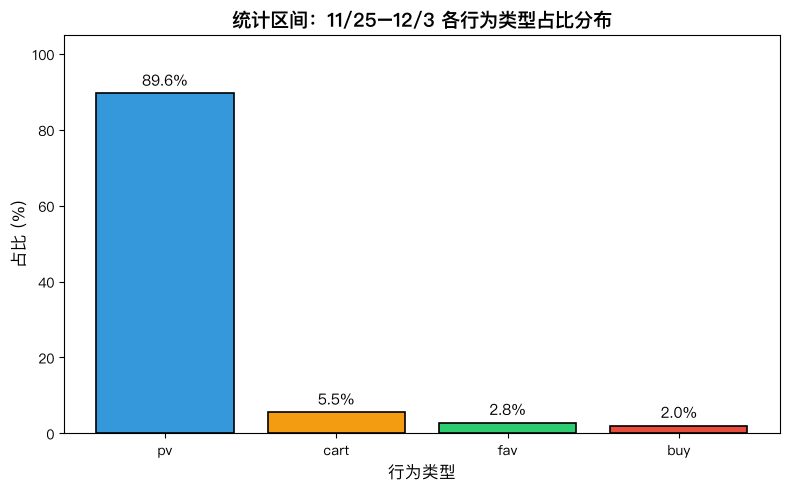

In [7]:
# 绘制行为类型占比图
# 颜色映射（全局复用：后续 5.2 / 5.3 / 5.4 章节统一使用，勿删）
color_map = {'pv': '#3498db', 'fav': '#2ecc71', 'cart': '#f39c12', 'buy': '#e74c3c'}
plot_behavior_distribution(behavior_percent, color_map)

### 1.2 用户行为频次分布

In [8]:
# 1.2 用户行为频次分布
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py
user_activity, activity_stats, stats_df = compute_user_activity_stats(df)

print("=" * 60)
print("统计区间：11/25–12/3 用户行为频次分布统计")
print("=" * 60)
print(tabulate(stats_df, headers='keys', tablefmt='pipe', showindex=False))
print("=" * 60)

# 解读信息
print("\n📌 解读：")
print(f"   • 平均每个用户产生约 {activity_stats['均值']:.0f} 次行为")
print(f"   • 中位数为 {activity_stats['中位数(50%)']:.0f} 次，说明半数用户行为次数低于这个值")
print(f"   • 最活跃用户产生了 {activity_stats['最大值']:.0f} 次行为")
print(f"   • 90% 的用户行为次数在 {activity_stats['90%分位']:.0f} 次以内")

统计区间：11/25–12/3 用户行为频次分布统计
| 统计指标    |    数值 |
|:------------|--------:|
| 用户数      | 9739    |
| 均值        |  102.63 |
| 标准差      |   88.72 |
| 最小值      |    2    |
| 中位数(50%) |   76    |
| 75%分位     |  137    |
| 90%分位     |  222    |
| 95%分位     |  279    |
| 99%分位     |  423    |
| 最大值      |  781    |

📌 解读：
   • 平均每个用户产生约 103 次行为
   • 中位数为 76 次，说明半数用户行为次数低于这个值
   • 最活跃用户产生了 781 次行为
   • 90% 的用户行为次数在 222 次以内


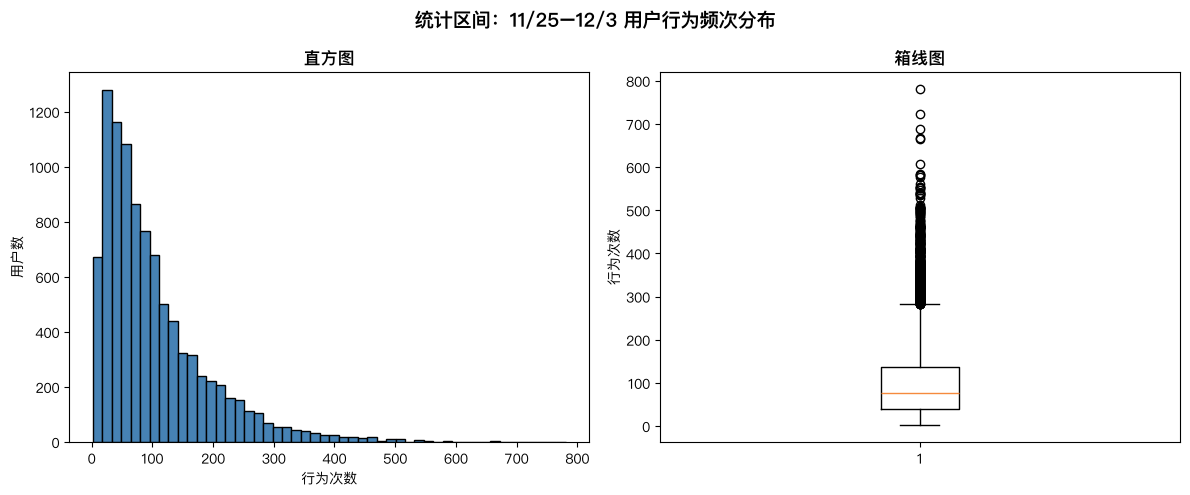

In [9]:
# 绘制行为频次分布直方图和箱线图
plot_user_activity_distribution(user_activity)

 从分布形态看，用户行为频次呈显著右偏长尾：直方图峰值落在约 30–50 次区间，随后随行为次数增加单调下降，绝大多数用户集中在低频段；箱线图显示中位数约 75 次、IQR 约 30–130 次，whisker 上限约 280 次，之上密集分布着大量离群点，最高超过 700 次。这说明用户活跃度高度不均——低频用户占主体，极少数高频用户拉出了长长的尾巴，这些头部用户可能是核心重度用户，也可能是爬虫或异常账号，建议后续单独分层并做剔除离群点后的敏感性对比。

### 1.3 离群点 / 机器人审查

**Motivation：**

上面的 1.2 章节发现行为频次右偏长尾、最高用户超 700 次行为。头部高度活跃用户可能是「核心重度用户」，也可能是「爬虫 / 异常账号」。本格用可复核信号（近乎全勤、日均强度过高、纯浏览零购买、单商品暴力点击）对头部用户做异常判定并给出处置建议，而非仅打印匿名 ID 排行榜。

In [10]:
# 1.3 离群点 / 机器人审查 —— 数据聚合（计算用户画像）
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py
user_profile, window_days = build_user_profile(df)

In [11]:
# 识别候选异常（逻辑判断）
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py
# 信号：近乎全勤（仅背景）/ 零购买高频 / 日均强度异常
REVIEW_N = 30  # 审查头部 30 个最活跃用户（极端长尾，可调）
top_users = flag_candidate_anomalies(user_profile, window_days, review_n=REVIEW_N)

In [12]:
# 打印汇总信息
print("=" * 60)
print(f"离群点 / 机器人审查：头部 {REVIEW_N} 最活跃用户（窗口 {window_days} 天）")
print("=" * 60)
print(f"头部 {REVIEW_N} 用户占全量行为比例："
      f"{top_users['behavior_count'].sum() / user_activity['behavior_count'].sum() * 100:.1f}%")
print(f"头部用户活跃天数中位数：{top_users['active_days'].median():.0f} 天（窗口共 {window_days} 天）")
print(f"头部用户购买率中位数：{(top_users['n_buy'] / top_users['behavior_count']).median() * 100:.1f}%")
print(f"候选异常账号数：{int(top_users['is_candidate_anomaly'].sum())} / {REVIEW_N}")
print("-" * 60)

离群点 / 机器人审查：头部 30 最活跃用户（窗口 9 天）
头部 30 用户占全量行为比例：1.7%
头部用户活跃天数中位数：9 天（窗口共 9 天）
头部用户购买率中位数：0.4%
候选异常账号数：10 / 30
------------------------------------------------------------


In [13]:
# 打印候选异常明细
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py（中文列名 + ✓/✗ 格式化）
anomaly_tbl, anomaly_tbl_display = format_anomaly_table(top_users)

print("10个候选异常账号明细（命中信号）：")
print(tabulate(anomaly_tbl_display, headers='keys', tablefmt='pretty', showindex=False))

10个候选异常账号明细（命中信号）：
+---------+-----------+----------+----------+------------+----------+------------+--------------+
| 用户ID  |  行为次数 | 活跃天数 | 购买次数 | 独立商品数 | 近乎全勤 | 零购买高频 | 日均强度异常 |
+---------+-----------+----------+----------+------------+----------+------------+--------------+
| 115477  |    781    |    9     |    0     |    606     |    ✓     |     ✓      |      ✓       |
| 116139  |    724    |    9     |    0     |    117     |    ✓     |     ✓      |      ✓       |
| 114912  |    689    |    7     |    3     |    411     |    ✗     |     ✗      |      ✓       |
| 115906  |    668    |    9     |    1     |    424     |    ✓     |     ✗      |      ✓       |
| 1010419 |    665    |    9     |    0     |    480     |    ✓     |     ✓      |      ✓       |
| 1014799 |    607    |    9     |    0     |    503     |    ✓     |     ✓      |      ✗       |
| 121233  |    582    |    7     |    0     |    433     |    ✗     |     ✓      |      ✓       |
| 125442  |    547    |    9     | 

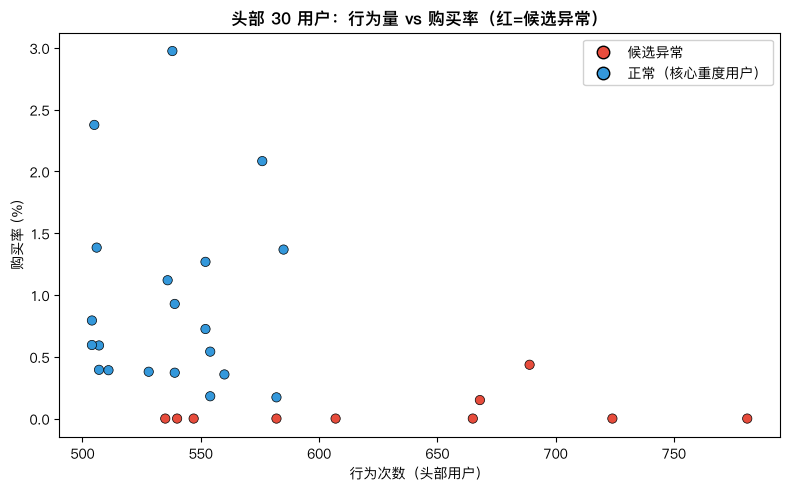

In [14]:
# 可视化 scatter plot: 行为量 vs 购买率
# 红 = 候选异常（零购买者购买率为 0，落在 y=0 底部，一眼可见）
plot_anomaly_scatter(top_users, REVIEW_N)

**结论** <br>

头部 30 最活跃用户仅占全量行为 **1.7%**，对整体结论影响可忽略。其中 **10 个候选异常（约 1/3）**，行为模式疑似脚本/异常账号：**8 个**命中「零购买高频」（500–780 次行为却 0 购买，疑似纯爬取/比价），**6 个**命中「日均强度超人类节律」（>70 次/天）；两类信号存在重叠——4 个账号同时命中，故 10 = 仅零购买高频 4 + 同时命中 4 + 仅强度异常 2。其余 20 个为信号未命中的真实重度用户。

处置：将上述候选异常标记为**数据质量 footnote**；因占比极小（<2%），**不剔除、不改后续漏斗与频次结论**。


### 1.4 用户分层概览

In [15]:
# 1.4 用户分层概览（统计区间：11/25–12/3，共 9 天）
# 实现已抽取至 src/ecommerce_conversion_analysis/eda.py
layers = build_user_layers(df, anomaly_tbl)
display(Markdown(render_layer_table(layers)))


| 用户分层 | 用户数 | 用户占比 | 行为量占比 | 备注 |
|----------|--------|----------|------------|------|
| 总用户 | 9,739 | 100% | 100% | 统计区间 11/25–12/3 |
| ├ 有购买行为的用户 | 6,689 | 68.7% | 75.7% | 观测窗内至少产生 1 次 buy |
| └ 纯浏览用户（无购买） | 3,050 | 31.3% | 24.3% | 仅产生 pv / fav / cart，无 buy |
| 其中：候选异常账号 | 10 | 0.1% | 0.6% | 零购买高频 8 人 + 日均强度异常 6 人（信号重叠，并集 10 人）|


## 二. 时间维度分析 （看趋势和规律）

### 2.1 每日趋势 —— 分析每日行为量和每日活跃用户数（DAU）的变化趋势

In [16]:
# 2.1 提取并计算每日行为量和 DAU
# 实现已抽取至 src/ecommerce_conversion_analysis/time_trends.py
daily_stats = compute_daily_trends(df)

In [17]:
# 打印每日趋势汇总表
# 实现已抽取至 src/ecommerce_conversion_analysis/time_trends.py（列名中文化）
print_df = format_daily_table(daily_stats)

print("=" * 60)
print("统计区间：11/25–12/3 每日行为量与活跃用户数")
print("=" * 60)
print(tabulate(print_df, headers='keys', tablefmt='pipe', showindex=False,
               numalign='center', stralign='center'))
print("=" * 60)

print(f"📊 总行为量: {daily_stats['behavior_count'].sum():,} 条")
print(f"👥 日均活跃用户 (DAU): {daily_stats['user_count'].mean():.0f} 人")
print(f"📈 日均行为量: {daily_stats['behavior_count'].mean():.0f} 条")

统计区间：11/25–12/3 每日行为量与活跃用户数
|  日期  |  行为量  |  活跃用户数  |  星期  |
|:------:|:--------:|:------------:|:------:|
| 11-25  |  104408  |     6976     |  周六  |
| 11-26  |  106576  |     7128     |  周日  |
| 11-27  |  97808   |     7026     |  周一  |
| 11-28  |  99099   |     7032     |  周二  |
| 11-29  |  102240  |     7141     |  周三  |
| 11-30  |  105587  |     7243     |  周四  |
| 12-01  |  109390  |     7270     |  周五  |
| 12-02  |  137774  |     9567     |  周六  |
| 12-03  |  136648  |     9561     |  周日  |
📊 总行为量: 999,530 条
👥 日均活跃用户 (DAU): 7660 人
📈 日均行为量: 111059 条


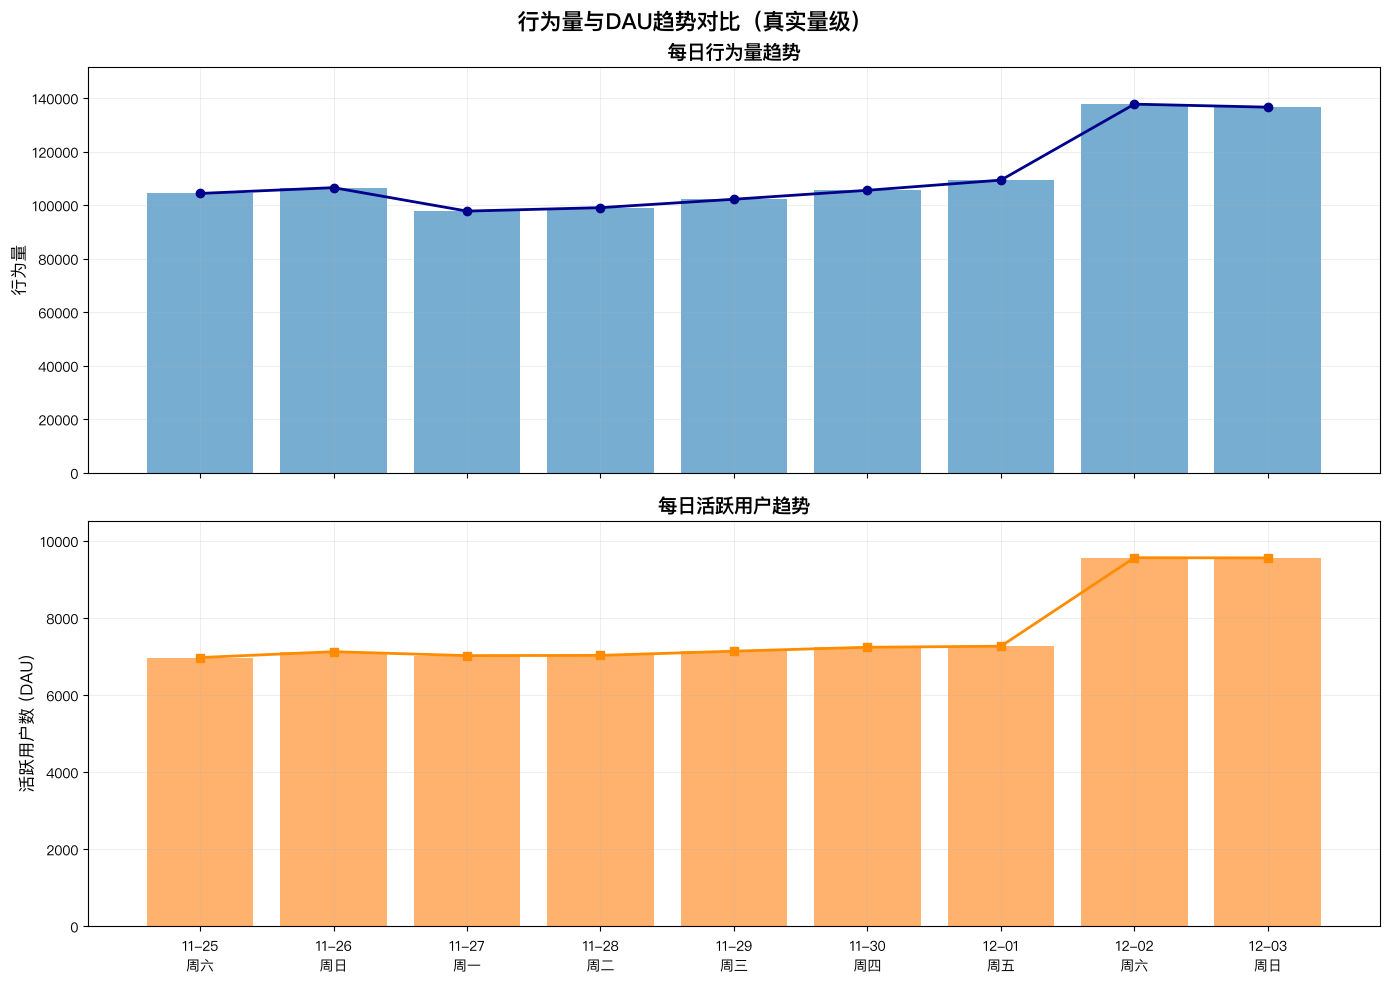

In [18]:
# 2.1 可视化：每日行为量 + DAU 双子图（共享 x 轴）
plot_daily_trends(daily_stats)

每日活跃用户数（DAU）与每日行为量趋势解读

- **11/25–12/3 期间，DAU 与每日行为量两条曲线高度同步**，说明日活变化由「更多用户进入 + 人均行为增多」共同驱动。本数据覆盖两个周末，但表现截然不同：

- **首个周末（11/25～11/26）行为量和DAU, 与普通工作日基本持平**，并未出现明显周末活跃抬升。工作日（11/27~12/1）：11/27（周一）为局部谷底，12/1（周五）开始爬升。

- **第二个周末 (12/02~12/03) 行为量与DAU均达到峰值**。该峰值不是「周末」本身造成，而是双 12 大促预热事件驱动，平台通常提前约 10 天启动预热。其中 **12/02 共有日活跃用户 9567 人 和 13,7774 次用户行为，是全周期行为量最高的一天**，12/03 共有日活跃用户 9561 人 和 13,6648 次紧随其后。

结论：日活波动的核心驱动是「大促事件」而非「星期几」。分析时应按「普通日 / 大促预热期」分组，并将 12/2–12/3 设为独立活动窗口，避免把单周异常峰值误读为周末规律。

**注：观测窗仅含2个周末，样本量过小，且周末/工作日差异仅作方向性参考，不具备强统计显著性。**

### 2.2 用户行为按小时分布

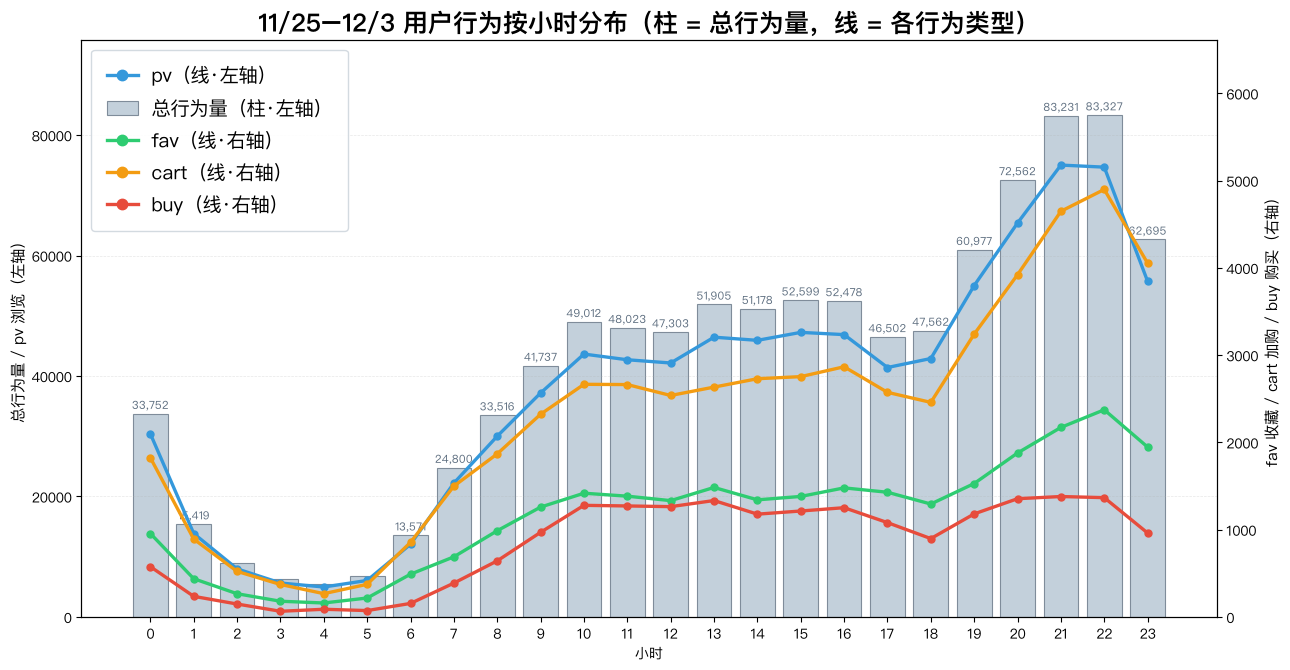

行为量最高的时段: 22:00-22:59，行为量 83,327 条


In [19]:
# 2.2 按小时分布：总行为量柱 + pv / fav / cart / buy 四条折线（双 y 轴）
# 实现已抽取至 src/ecommerce_conversion_analysis/time_trends.py
# compute_hourly_behavior 同时返回总行为量与各行为透视，
# 修复此前 hourly_behavior 未定义导致的 NameError
hourly_behavior, hourly_pivot = compute_hourly_behavior(df)
plot_hourly_behavior(hourly_behavior, hourly_pivot, color_map)

# 打印峰值时段
peak_hour = hourly_behavior.loc[hourly_behavior['behavior_count'].idxmax()]
print(f"行为量最高的时段: {peak_hour['hour']}:00-{peak_hour['hour']}:59，"
      f"行为量 {peak_hour['behavior_count']:,} 条")

**峰值时段与整体节奏**
全天行为量最高的是 22:00–22:59（**83,327** 条），21:00 紧随其后（83,231 条），两者几乎持平，形成晚间「黄金两小时」。曲线呈典型电商日内双峰结构：凌晨 2:00–5:00 触底（最低 5,484 条），8:00 起快速爬升，10:00 达约 4.9 万并维持 10:00–16:00 高位平台期，19:00 起再次陡峭爬升，19:00–22:00 三小时涨幅约 **37%**。

**四条行为曲线：同构，但平缓度差很多**
pv / fav / cart / buy 四曲线形状高度同构（均凌晨触底、早间爬坡、20–22 点达峰），但**平缓度差异显著**：白天 10–16 点，pv 仅维持其峰值的 60%、fav 约 59%、cart 约 55%，而 **buy 高达 91%**。购买行为的日内分布远比浏览平坦，说明下单受「闲暇时段」的驱动明显弱于浏览、收藏与加购。

**结合双十二预热背景**
数据采集期为 2017-11-25 至 12-03，正值双十二（12-12）前约 10–17 天。12/1 前后平台通常启动预热（预售定金、品类券、加购清单等），会显著推高晚间行为量；晚间 19:00–23:00 的陡峭爬升与「下班后刷淘宝、抢券 / 加购」场景高度吻合。若与 11/25–11/30 非预热期拆线对比，12/1–12/3 的晚间曲线大概率更高、更陡（可作为后续验证方向）。

**运营启示**
- **曝光资源**（推荐位 / push / 直播开播）→ 20:00–23:00，吃流量红利，其中 21:00–22:00 为绝对黄金窗口；
- **转化动作**（发券 / 秒杀 / 定向优惠）→ 10:00–16:00，此时段流量虽只有晚间的六成，但这段时间内Buy的行为量显然更高；
- **凌晨 2:00–6:00** 为低价值窗口，适合系统维护、模型训练等非实时任务，或降低推荐服务配给。


## 三. 商品维度分析（看品类和商品热度）

### 3.1 热销品类与商品 TOP 10（按行为量）

回答"什么火"的两条基线：品类级（该重点投放哪个品类）与商品级（该主推哪个 SKU）。

In [20]:
# 3.1 行为量统计（TOP10）：热销品类 + 热销商品
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
top_stats = compute_top_categories_items(df, top_n=10)
top_categories = top_stats['top_categories']
top_items = top_stats['top_items']
top_items_with_category_total = top_stats['top_items_with_category_total']
n_cat, n_item = top_stats['n_cat'], top_stats['n_item']

全量：5,793 个品类 / 398,971 个商品
TOP10 品类行为量占比：27.3%（TOP10 品类数占全量的 0.17%）
TOP10 商品行为量占比：0.2%
TOP10 商品 item_share 中位数：0.7%


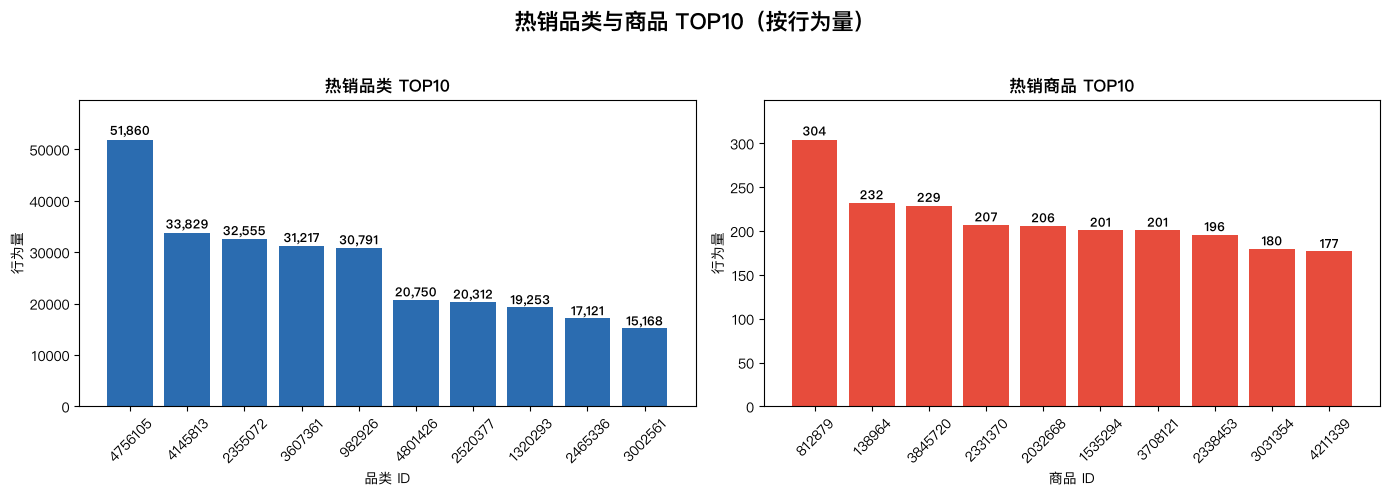

In [21]:
print(f"全量：{n_cat:,} 个品类 / {n_item:,} 个商品")
print(f"TOP10 品类行为量占比：{top_categories['behavior_count'].sum() / len(df) * 100:.1f}%"
      f"（TOP10 品类数占全量的 {len(top_categories) / n_cat * 100:.2f}%）")
print(f"TOP10 商品行为量占比：{top_items['behavior_count'].sum() / len(df) * 100:.1f}%")
print(f"TOP10 商品 item_share 中位数：{top_items_with_category_total['item_share'].median():.1f}%")

# 3.1 可视化：热销品类 TOP10 + 热销商品 TOP10（1×2 子图）
plot_top_categories_items(top_categories, top_items)

**解读**

- 全量行为共 999,530 条， 其中包含 5,793 个品类和 398,971 个商品。

- Top10 品类贡献了 27.3% 的行为量；而 TOP10 商品仅贡献 0.2% 的行为量，数据说明无"单品通吃"现象。该行为量占比从上面两张图片也可看出，Top10 品类行为量范围 15,168~51,860, 然而 Top10 商品行为量范围 177～304）

- 另外Top10 商品的 item_share 中位数仅 **0.7%**, 这表明头部品类的热度并非由头部商品单点撑起，而是品类内大量商品共同贡献。*注：item_share = 该商品行为量 / 所属品类总行为量 × 100*

### 3.2 热销商品多维画像

#### 3.2.1 Top 10 商品热度与品类结构

In [22]:
# 3.2.1 预备数据：品类→商品映射 + 统一配色 + 品类行为类型构成
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
category_group, item_colors, bt_cat, bt_pct = prepare_item_category_view(
    df, top_items_with_category_total)

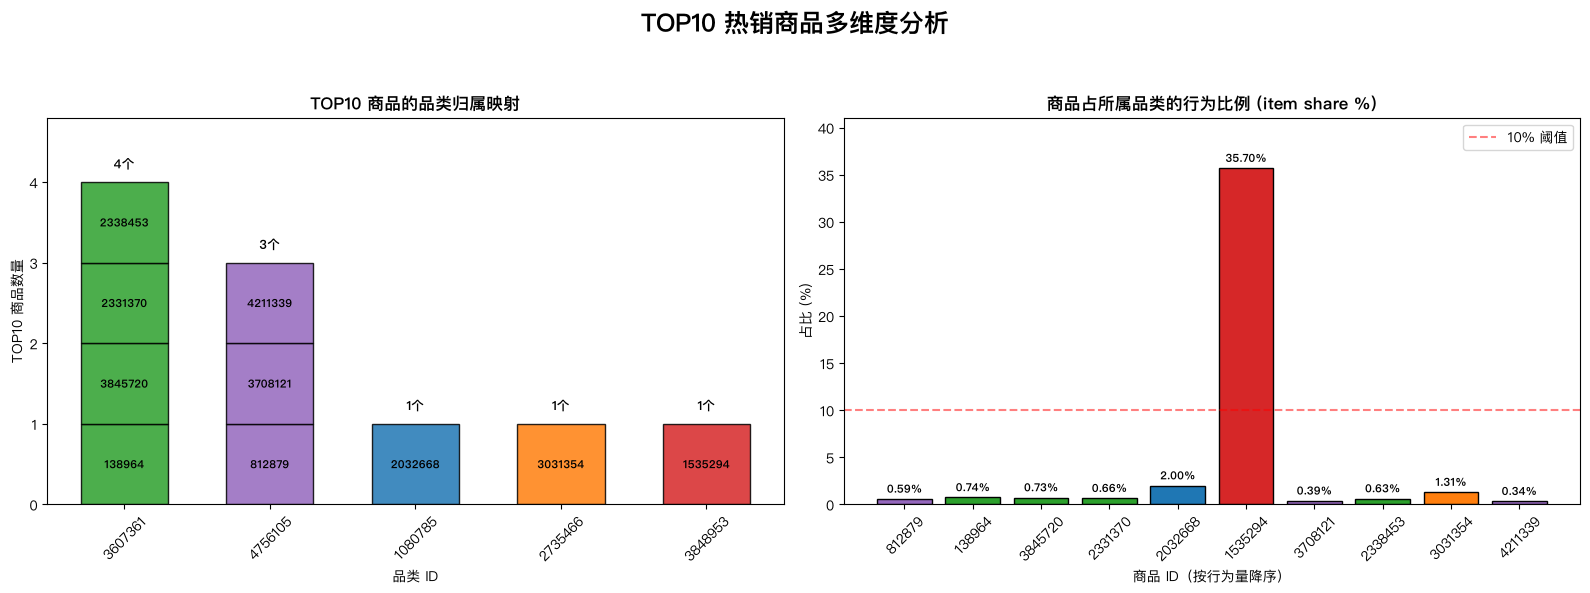

In [23]:
# 3.2.1 可视化：TOP10 商品品类归属映射 + 商品 item_share
plot_item_category_structure(top_items_with_category_total, category_group, item_colors)

In [24]:
# 查询商品 ID 1535294 的品类 ID
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
target_item = 1535294
cat_id, target_cat_behavior = query_item_category(df, target_item)

print("=" * 60)
print(f"商品ID {target_item} 的 品类ID 是: {cat_id}")
print(f"品类总行为数: {target_cat_behavior:,} 条")

商品ID 1535294 的 品类ID 是: 3848953
品类总行为数: 563 条


**解读**

- 左图表明 **品类 3607361** 和 **4756105** 分别独占 4 个和 3 个Top10 商品。 --> TOP10 商品扎堆于两个品类， 头部商品在品类归属上高度聚集：。

- 右图表明 Top10 商品中 9 个占所属品类中的行为比例很低（item_share 中位数 0.7%）,说明品类热度由品类内大量商品共同贡献。

- 而**商品ID 1535294** 占所属品类的行为竟高达 35.70%； 经查验，该商品位于总行为仅 **563** 的小品类 **3848953** 中，说明该商品和品类可能比较小众，且**商品ID 1535294**在这个小品类里影响力强。

#### 3.2.2 TOP10 商品所属品类下的行为构成（堆叠柱状图）

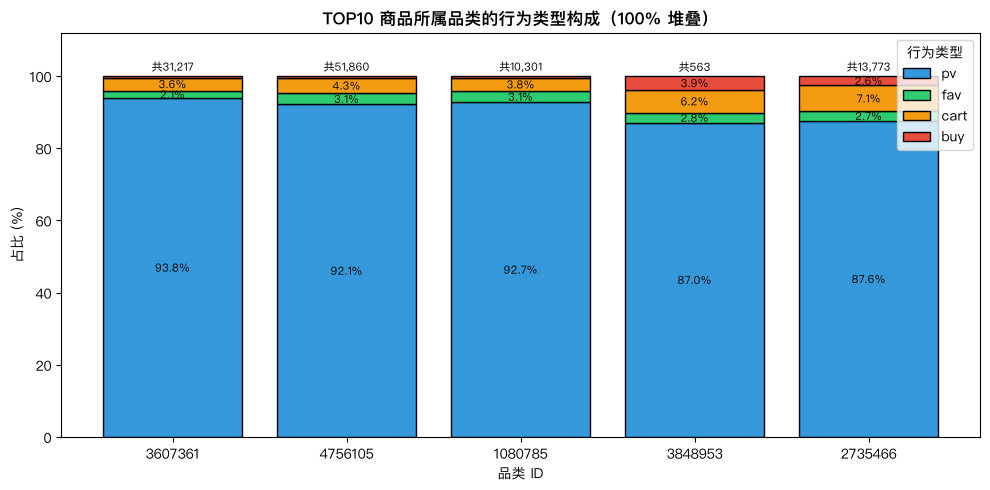

buy 行为占比（按品类，%）：{3607361: 0.46, 4756105: 0.5, 1080785: 0.44, 3848953: 3.91, 2735466: 2.64}
buy 占比中位数：0.50% | 最小 0.44% | 最大 3.91%


In [25]:
# 3.2.2 TOP10 商品所属品类的行为类型构成（100% 堆叠柱状图）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
plot_category_behavior_composition(bt_cat, bt_pct)

# buy% 显式输出（堆叠图中 buy 在大体量品类 <0.5% 不可见，单独打印审计）
buy_pct = bt_pct['buy'].round(2).to_dict()
print(f"buy 行为占比（按品类，%）：{buy_pct}")
print(f"buy 占比中位数：{bt_pct['buy'].median():.2f}% | 最小 {bt_pct['buy'].min():.2f}% | 最大 {bt_pct['buy'].max():.2f}%")

**头部品类行为构成以浏览绝对主导**：pv 在 5 个品类中占比 **87.0%~93.8%**，fav 与 cart 各占 2.1%~7.1%，**buy 占比最低（0.4%~3.9%）**。

buy 在不同品类间差异显著：
- **3 个大体量品类（3607361、4756105、1080785）的 buy 占比仅 0.4%~0.5%**，堆叠图中红色段极薄（因 pv 占 90%+）；
- 品类 3848953（buy 3.9%）和 2735466（buy 2.6%）明显偏高：
  - 前者样本小（总行为 563）属小样本噪声；
  - 后者（13,773 行为）属可信信号。

**结论**：头部品类整体呈现 **"看得多、买得少"** 的浏览型行为模式，购买转化存在品类间结构性分化。

**建议**：
1. 针对 **2735466** 等购买占比显著高于均值的品类，建议运营侧优先拆解其转化路径（如搜索词来源、详情页停留时长、促销触达方式），「建议通过 A/B 实验验证后再迁移，本报告无法验证因果关系」。
2. 对于 **3607361、4756105、1080785** 三个大体量低转化品类，建议聚焦 **fav→cart→buy** 的中间环节流失，重点分析加购后未支付的原因（如运费、价格、库存），而非盲目扩大流量。

### 3.3 品类内商品集中度

 category_id   商品数  总行为量  CR1%  CR5%    HHI
     3607361  6857 31217  0.74  3.22 0.0008
     4756105 10514 51860  0.59  1.90 0.0005
     1080785  3291 10301  2.00  5.26 0.0017
     3848953    92   563 35.70 57.73 0.1454
     2735466  3187 13773  1.31  4.70 0.0016
CR1 中位数：1.3% | CR5 中位数：4.7%


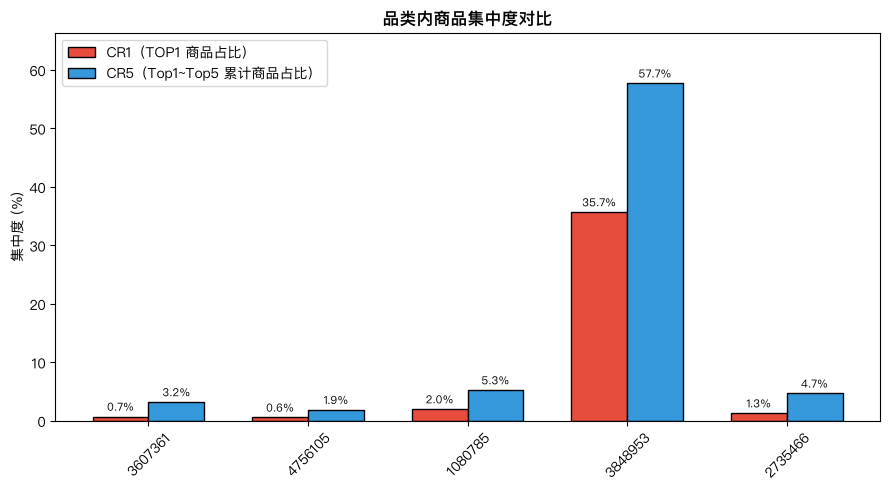

In [26]:
# 3.3 品类内商品集中度（CR1 / CR5 / HHI）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
cat_order = (top_items_with_category_total.groupby('category_id')['behavior_count']
             .sum().sort_values(ascending=False).index.tolist())
conc = compute_category_concentration(df, cat_order)
print(conc.to_string(index=False))
print("=" * 60)
print(f"CR1 中位数：{conc['CR1%'].median():.1f}% | CR5 中位数：{conc['CR5%'].median():.1f}%")

plot_category_concentration(conc)

集中度指标坐实"长尾驱动"：头部品类 **CR1 中位数 1.3%、CR5 中位数 4.7%**，最大品类 4756105（10,514 个商品）的 HHI 仅 0.0005，没有任何单品能主导品类行为；唯一高集中度品类 3848953（CR1=35.7%、HHI=0.145）仅含 92 个商品、总行为 563，属小样本噪声，不具业务代表性。**结论：头部品类由长尾商品共同支撑，而非少数爆款拉动。**


### 3.4 各品类的购买转化率分析
转化率定义: 既有浏览又有购买的用户数 / 总浏览用户数

#### 3.4.1 计算每个品类的转化率

In [27]:
# 3.4.1 计算每个品类的转化率（用户级：既浏览又购买 / 总浏览用户）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
conversion_df = compute_category_conversion(df)

print(f"共有 {len(conversion_df)} 个品类有浏览记录")
print(conversion_df[['category_id', 'total_browser', 'converted_users', 'conversion_rate_pct']].head())

共有 5701 个品类有浏览记录
   category_id  total_browser  converted_users conversion_rate_pct
0         2171             10              1.0               10.0%
1         2410              6              0.0                0.0%
2         3579              2              0.0                0.0%
3         4907              1              0.0                0.0%
4         5064             56              1.0               1.79%


全品类转化率分布总览（为什么需要阈值过滤）

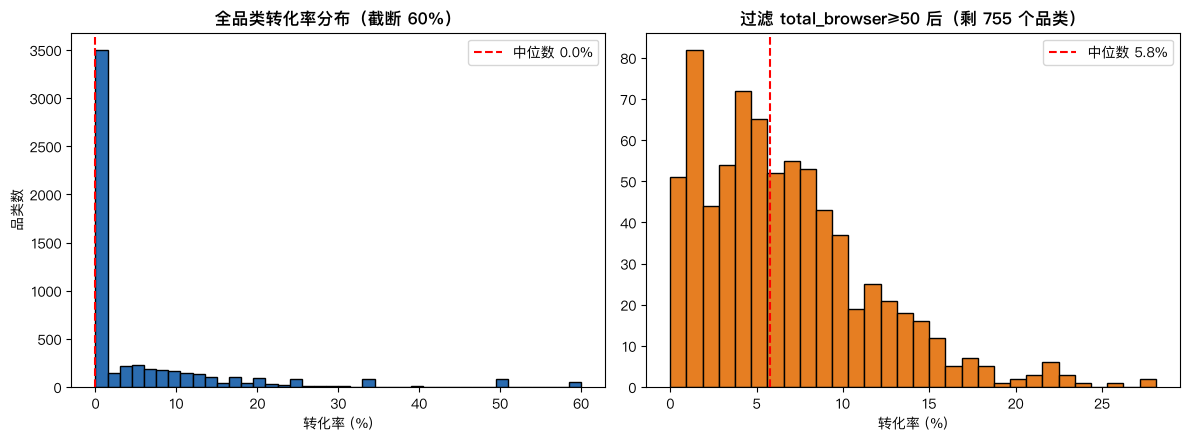

In [28]:
# 3.4.1 全品类转化率分布总览（回答：为什么必须过滤小样本）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
valid = plot_conversion_distribution(conversion_df, min_browser=50)

In [29]:
print(f"全品类转化率分布（共 {len(conversion_df)} 个品类有 pv 记录）:")
print(conversion_df['conversion_rate'].describe(
    percentiles=[.25, .5, .75, .9, .95, .99]).round(2).to_string())

全品类转化率分布（共 5701 个品类有 pv 记录）:
count    5701.00
mean        5.94
std        12.85
min         0.00
25%         0.00
50%         0.00
75%         7.41
90%        17.11
95%        25.86
99%        50.00
max       100.00


全品类（5,701 个有 pv 品类）转化率呈**"零膨胀 + 小样本虚高"**的噪声形态：**中位数 0%**（一半品类零购买）、P99 达 50%、最大 100%（单人浏览单人购买的小样本）。**阈值 50 过滤后仅剩 755 个有效品类（过滤掉 86.8%）**，分布恢复健康：**中位数 5.8%、P25 3.0%、P90 13.4%、最大 28.1%**。量化铁证：过滤前转化率>10% 的 1,103 个品类中 948 个（86%）为 <50 人浏览的小样本，虚高不具统计意义——这正是 3.4.2 起阈值敏感性分析的直接动因，也坐实 3.4.6 选择 **threshold = 50** 的合理性。

#### 3.4.2 阈值敏感性分析 选择 thresholds = [10, 30, 50, 100, 200]

In [30]:
# 3.4.2 阈值敏感性分析：分别用不同阈值跑 TOP10，看排名变化
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
thresholds = DEFAULT_THRESHOLDS
sensitivity_analysis_results, top10_ids = compute_threshold_sensitivity(conversion_df, thresholds)

# 打印每个阈值下的 TOP10
for th in thresholds:
    print("=" * 70)
    print(f"阈值 = {th}（共 {len(conversion_df[conversion_df['total_browser'] >= th])} 个品类）")
    print("=" * 70)
    print(sensitivity_analysis_results[th][['rank', 'category_id', 'total_browser',
                                            'converted_users', 'conversion_rate']].to_string(index=False))
    print("\n")

阈值 = 10（共 2284 个品类）
 rank  category_id  total_browser  converted_users  conversion_rate
    1      1030192             10              5.0            50.00
    2       166326             11              5.0            45.45
    3       719442             17              7.0            41.18
    4       257909             10              4.0            40.00
    5      2003083             11              4.0            36.36
    6      3940193             14              5.0            35.71
    7      1829804             31             11.0            35.48
    8      2627103             12              4.0            33.33
    9      4835206             18              6.0            33.33
   10      2883724             24              8.0            33.33


阈值 = 30（共 1120 个品类）
 rank  category_id  total_browser  converted_users  conversion_rate
    1      1829804             31             11.0            35.48
    2       804084             35             11.0            31.43
    3 

#### 3.4.3 对比各阈值下的 TOP10 品类排名变化

In [31]:
# 3.4.3 对比各阈值下的 TOP10 品类排名变化
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
print("=" * 60)
print("不同阈值下 TOP10 品类的重合度分析")
print("=" * 60)

for th1, th2, overlap_n in compute_top10_overlap(top10_ids, thresholds):
    print(f"阈值 {th1} 和 {th2} 的重合品类数: {overlap_n}/10")

不同阈值下 TOP10 品类的重合度分析
阈值 10 和 30 的重合品类数: 1/10
阈值 10 和 50 的重合品类数: 0/10
阈值 10 和 100 的重合品类数: 0/10
阈值 10 和 200 的重合品类数: 0/10
阈值 30 和 50 的重合品类数: 3/10
阈值 30 和 100 的重合品类数: 0/10
阈值 30 和 200 的重合品类数: 0/10
阈值 50 和 100 的重合品类数: 3/10
阈值 50 和 200 的重合品类数: 1/10
阈值 100 和 200 的重合品类数: 3/10


#### 3.4.4 用交集法选择稳定核心品类

In [32]:
# 3.4.4 用交集法选择稳定核心品类
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
core_set = find_core_categories(top10_ids, thresholds)

print("=" * 60)
print(f"在所有阈值（{'/'.join(map(str, thresholds))}）下都进入 TOP10 的品类：")
print("=" * 60)
if core_set:
    core_data = conversion_df[conversion_df['category_id'].isin(core_set)]
    print(core_data[['category_id', 'total_browser', 'converted_users', 'conversion_rate']]
          .sort_values('conversion_rate', ascending=False).to_string(index=False))
else:
    print("没有品类在所有阈值下都进入 TOP10，说明高转化品类对阈值敏感")

在所有阈值（10/30/50/100/200）下都进入 TOP10 的品类：
没有品类在所有阈值下都进入 TOP10，说明高转化品类对阈值敏感


#### 3.4.5 可视化排名变化

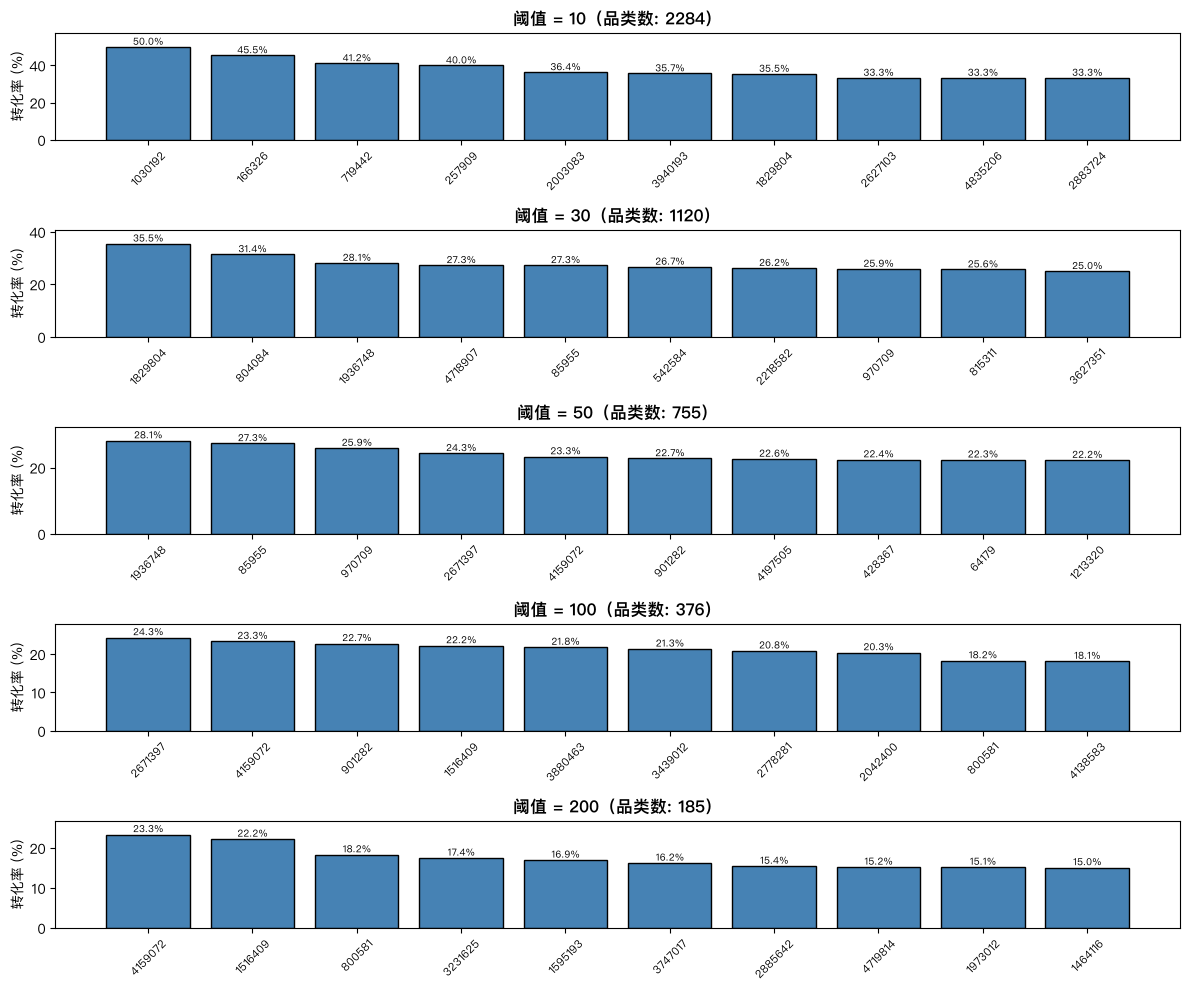

In [33]:
# 3.4.5 可视化：不同阈值下 TOP10 的转化率分布（纵向分面柱状图）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
# 注意：本图保持分面柱状图，勿改为折线图
plot_threshold_sensitivity(sensitivity_analysis_results, conversion_df, thresholds)

#### 3.4.6 阈值选择的分析报告

**阈值选择分析：为什么是 50？**

在计算品类转化率时，面临一个经典的**“样本量与稳定性”权衡**问题。阈值过低会引入大量噪声（小样本偏差）；阈值过高则会过滤掉有价值的潜力品类。

**分析过程：**

通过敏感性分析，观察了不同阈值（10, 30, 50, 100, 200）下，TOP10 高转化品类的排名变化情况。

**低阈值（≤30）的局限性：**

- 当阈值设置为 10 或 30 时，TOP10 榜单主要由**样本量极小的冷门品类**主导。例如，阈值 10 时，TOP10 中多个品类的浏览人数仅为 10–20 人。
- 这些品类的转化率波动极大（如 50%、45.45%），主要由**1–5 个用户的购买行为**决定，在统计学上缺乏显著性，无法真实反映品类的长期转化能力。
- **重合度分析**显示：阈值 10 与阈值 50 的 TOP10 重合品类数为 **0/10**，说明低阈值下筛选出的高转化品类极不稳定，结论不可靠。

**高阈值（≥100）的局限性：**

- 当阈值提高到 100 时，虽然保证了样本的稳定性，但过滤掉了超过一半的活跃品类（从 755 个降至 376 个）。
- 这可能使我们错失一些**“潜力品类”**——即当前流量不大，但已展现出较高转化效率的品类。例如：

  - 品类 `1936748`，浏览 64 次，转化率 28.12%

**决策依据：**

综合考虑后，选择**阈值 50**作为计算转化率的最优参数：

- **可信度达标：** 50 个浏览用户的门槛，将样本误差控制在可接受范围内，过滤了绝大部分小样本噪声。
- **稳定性确认：** 阈值 50 的 TOP10 与阈值 100 的 TOP10 重合度达到 **3/10**，且高重合的品类（如 `4159072`、`1516409`）均为样本量较大、转化率稳定的品类。说明阈值 50 筛选出的高转化品类是“真实的”，不会因阈值的微小变动而剧烈波动。
- **业务灵敏度：** 相较于阈值 100，阈值 50 保留了更多处于成长期的潜力品类，为运营提供了更早的干预窗口，提升了分析的前瞻性。

**结论：**

本分析采用**总浏览人数 ≥ 50**作为品类转化率计算的有效样本阈值。在此口径下，获得了兼顾统计显著性（非偶然波动）与业务价值（包含潜力品类）的高转化品类列表，为后续策略制定提供了稳健的数据基础。

#### 3.4.7 查看转化率最高的 TOP10 品类（过滤浏览量 < 50 的品类）

In [34]:
# 3.4.7 查看转化率最高的 TOP10 品类（过滤浏览量 < 50 的品类）
# 实现已抽取至 src/ecommerce_conversion_analysis/item_category.py
display_df = get_top_conversion_categories(conversion_df, min_browser=50, top_n=10)

print("=" * 60)
print("购买转化率 TOP10 品类（浏览人数 ≥ 50，修正口径）")
print("=" * 60)
print(tabulate(display_df, headers='keys', tablefmt='pretty', showindex=False))
print("=" * 60)

购买转化率 TOP10 品类（浏览人数 ≥ 50，修正口径）
+---------+----------+----------+-----------+
| 品类ID  | 浏览人数 | 购买人数 | 转化率(%) |
+---------+----------+----------+-----------+
| 1936748 |    64    |   18.0   |  28.12%   |
|  85955  |    88    |   24.0   |  27.27%   |
| 970709  |    58    |   15.0   |  25.86%   |
| 2671397 |   103    |   25.0   |  24.27%   |
| 4159072 |   485    |  113.0   |   23.3%   |
| 901282  |   132    |   30.0   |  22.73%   |
| 4197505 |    62    |   14.0   |  22.58%   |
| 428367  |    67    |   15.0   |  22.39%   |
|  64179  |    94    |   21.0   |  22.34%   |
| 1213320 |    54    |   12.0   |  22.22%   |
+---------+----------+----------+-----------+


## 四. 行为路径与转化分析

**核心业务问题：** 用户从第一次接触商品到最终下单，中间到底走了什么路径、花了多久？

- **4.1 路径【长度】   用户级·跨全平台商品**  → 某次购买，其"距上一次购买（或样本起点）" 总共产生了多少 pv/fav/cart 的行为。只看下单的结果，不看下单的具体是哪件商品。
- **4.2 路径【模式】   商品级·单商品**   → 购买一件商品之前，走了什么路径？所有路径都与该商品有关，pv/fav/cart其他商品不计入。
- **4.3 路径【品类差异】 商品级·按品类** → 不同品类路径结构有何不同？
- **4.4 路径【耗时】   商品级·单商品**  → 从首接触到购买花多久？

**区分零间隙和空路径的概念，不然第四章下面的 subsection 关于零间隙和空路径的描述容易分不清！**

- **4.1 零间隙（用户级·跨商品）**：某次购买，其"距上一次购买（或样本起点）"窗口内非购买行为计数 = 0；不区分商品，所有 pv/fav/cart 都计入。

- **4.2/4.3/4.4 空路径（商品级·单商品）**：对特定 (user, item)，本次购买前该用户对该商品无任何 pv/fav/cart 接触；其他商品的行为不影响本商品判定。

⚠️ 4.1 与 4.2–4.4 是两套口径（用户级跨商品 vs 商品级单商品），**是两种不同的分析思路和方法，千万不要混淆概念！！！**。

### 4.1 (A) 跨全平台商品的购买前行为路径长度分析

**目标**：用户整体的购买行为结构：是冲动直购还是逛后购买？忠于同品还是不断换品？<br>
**口径**：按用户时间排序，对每一次 `buy` 事件统计其上一次购买之后到本次购买之前的 pv/fav/cart 次数（首购从样本起点计）；

In [35]:
# 4.1 购买前行为路径长度（口径·区间 / since-last-purchase）
pre_purchase = compute_pre_purchase_gaps(df)
path_since_last_purchase = pre_purchase['gap_before_purchase']

def summarize(s, name):
    d = s.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    d.index = ['buy 样本数', '均值', '标准差', '最小值', 'P25', '中位数',
               'P75', 'P90', 'P95', 'P99', '最大值']

    # 构建表格数据
    table_data = []
    for idx, val in d.items():
        table_data.append([idx, round(val, 2)])

    # 添加路径长度=0的占比行
    zero_ratio = (s == 0).mean() * 100
    table_data.append(['路径长度=0 占比', f'{zero_ratio:.1f}%'])

    # 打印标题
    print(f"\n=== {name}（n={len(s):,}）===")

    # 使用tabulate输出美化表格
    print(tabulate(table_data,
                   headers=['统计指标', '数值'],
                   tablefmt='pretty',
                   colalign=('left', 'right')))

summarize(path_since_last_purchase, '区间路径长度（每次购买，since-last-purchase）')


=== 区间路径长度（每次购买，since-last-purchase）（n=20,359）===
+-----------------+---------+
| 统计指标        |    数值 |
+-----------------+---------+
| buy 样本数      | 20359.0 |
| 均值            |   24.71 |
| 标准差          |   37.97 |
| 最小值          |     0.0 |
| P25             |     1.0 |
| 中位数          |    11.0 |
| P75             |    32.0 |
| P90             |    67.0 |
| P95             |    97.0 |
| P99             |   183.0 |
| 最大值          |   452.0 |
| 路径长度=0 占比 |   20.6% |
+-----------------+---------+


**一、分布形态：典型右偏长尾**
均值 **24.71** ≫ 中位数 **11**（均值约为中位数的 **2.25** 倍），标准差 **37.97** 超过均值，表明**分布严重右偏且离散度高**。这意味着多数购买的"前序间隙"集中在较低区间，少数购买被拉得很长，不能用均值代表"典型用户"——中位数（**11** 次）才是更有代表性的中心趋势度量。

**二、分位数刻画（n=20,359）**
- **P25 = 1、中位数 = 11**：半数购买的间隙仅 ≤11 次非购买行为；25% 的购买前几乎无前置浏览（≤1 次）。
- **P75 = 32、P90 = 67**：上四分位用户在前一次购买后经历了 32 次以上行为，10% 的高介入购买前序达 67 次以上。
- **P95 = 97、P99 = 183、最大值 = 452**：尾部极长，约 1% 的购买前序超过 183 次行为，最长单段达 452 次。这属于"高比较成本 / 决策犹豫"型购买，是长尾中的长尾。

### 4.1 (B) 零间隙购买分解：首购 vs 复购

In [36]:
# 4.1 补充：把 20.6% 拆成 首购零间隙 / 复购直接回购（2 类）
first_purchases  = pre_purchase[pre_purchase['purchase_seq'] == 1]
repeat_purchases = pre_purchase[pre_purchase['purchase_seq'] >= 2]

def zero_rate(s):
    return f"{(s.eq(0).sum() / len(s) * 100):.1f}%"

print(f"总购买事件:          {len(pre_purchase):,}")
print(f"首购事件:            {len(first_purchases):,}")
print(f"复购事件:            {len(repeat_purchases):,}")
print(f"首购零间隙:          {int(first_purchases['gap_before_purchase'].eq(0).sum()):,} "
      f"/ {len(first_purchases):,} = {zero_rate(first_purchases['gap_before_purchase'])}")
print(f"复购直接回购(零间隙): {int(repeat_purchases['gap_before_purchase'].eq(0).sum()):,} "
      f"/ {len(repeat_purchases):,} = {zero_rate(repeat_purchases['gap_before_purchase'])}")
print(f"合计零间隙占全部购买: {zero_rate(pre_purchase['gap_before_purchase'])}")

# ---------- 4.1 补充（二）：零间隙 4 类拆分（首购 / 同品复购 / 换品复购） ----------


classified = classify_pre_purchase_gaps(df)
total = len(classified)

print("\n--- 零间隙 4 类拆分（口径 A）---")
for label, key in [('首购', 'first'),
                   ('同品复购', 'same_item_rebuy'),
                   ('换品复购', 'diff_item_rebuy')]:
    sub = classified[classified['purchase_type'] == key]
    n = len(sub)
    z = int((sub['gap_before_purchase'] == 0).sum())
    print(f"{label:6s}: 事件 {n:,} | 零间隙 {z:,} "
          f"| 组内零间隙率 {z/n*100:.1f}% | 占全部购买 {z/total*100:.1f}%")

z_all = int((classified['gap_before_purchase'] == 0).sum())
print(f"合计零间隙: {z_all:,} = {z_all/total*100:.1f}%")



总购买事件:          20,359
首购事件:            6,689
复购事件:            13,670
首购零间隙:          364 / 6,689 = 5.4%
复购直接回购(零间隙): 3,834 / 13,670 = 28.0%
合计零间隙占全部购买: 20.6%

--- 零间隙 4 类拆分（口径 A）---
首购    : 事件 6,689 | 零间隙 364 | 组内零间隙率 5.4% | 占全部购买 1.8%
同品复购  : 事件 1,020 | 零间隙 302 | 组内零间隙率 29.6% | 占全部购买 1.5%
换品复购  : 事件 12,650 | 零间隙 3,532 | 组内零间隙率 27.9% | 占全部购买 17.3%
合计零间隙: 4,198 = 20.6%


**零间隙解读**

- 在**全部 20,359 次购买事件**中，有 **20.6%** 的购买事件未发生任何浏览/收藏/加购行为（即"零间隙"购买）。进一步按购买类型拆解，该比例的构成呈现显著分化：

- **首购零间隙（364 次，占首购 5.4%）**：
  该比例极低，且需注意本数据样本自 2017-11-25 起算，用户在此之前的浏览行为不可观测，因此这部分"零间隙首购"很可能是**左删失导致的观测截断**，不代表真实的"零决策首购"，解读时应避免归因于用户冲动消费。

- **同品复购零间隙（302 次，占同品复购 29.6%）**：
  接近三成的同品复购无需中间行为，反映用户对特定商品的**强忠诚度或刚需补货**，决策路径极短。

- **换品复购零间隙（3,532 次，占换品复购 27.9%）**：
  与同品复购水平相近，说明即便更换品类，老用户仍可能基于对平台/品牌/店铺的信任而快速成交，无需重新比价或浏览。
---
**口径与边界说明（避免误读）**

- **"28.0% 复购零间隙"是事件维度**，表示每笔复购订单中有 28% 无前置行为；若需描述"发生过零间隙复购的用户占比"，应按用户 ID 去重计算，数值会不同。
- **零间隙包含两种业务场景**：① 跨日/跨周的"回头复购"；② 同一会话内连续下单（如批量加购后一次性支付）。建议后续按 `timestamp` 时间间隔进一步切分，以区分"记忆复购"与"会话内连买"。
- 本指标基于 **9 天样本**，属样本内描述性统计，不可直接外推至全量或用于因果推断。

---
**业务启示**
- **首购用户**  零间隙率仅 5.4%，绝大多数首购依赖浏览/加购等前置行为，优化商品发现效率（搜索/推荐/榜单），缩短首购决策路径；降低新客试用门槛（如首单优惠、无忧退换）
- **复购用户**  零间隙率达 28.0%，已形成路径依赖或信任惯性，强化触发式触达（补货提醒、会员日回购权益）；利用"一键复购""常购清单"等产品功能进一步降低操作成本

> 核心结论：**新客运营重在"缩短首次决策路径"，老客运营重在"放大低摩擦回购惯性"**——两者并非同一套逻辑，资源投放应区别对待。

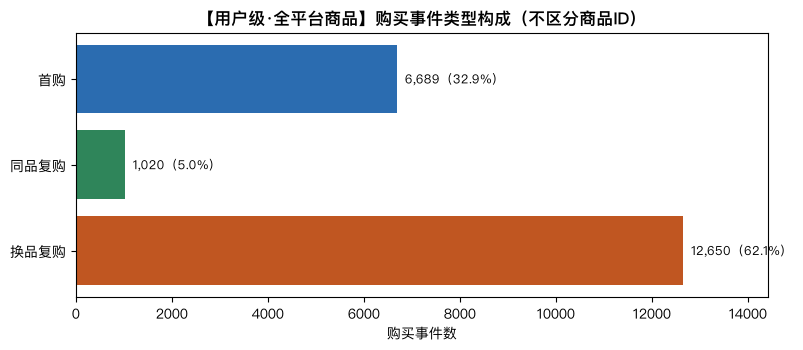

In [37]:
plot_purchase_type_composition(classified)

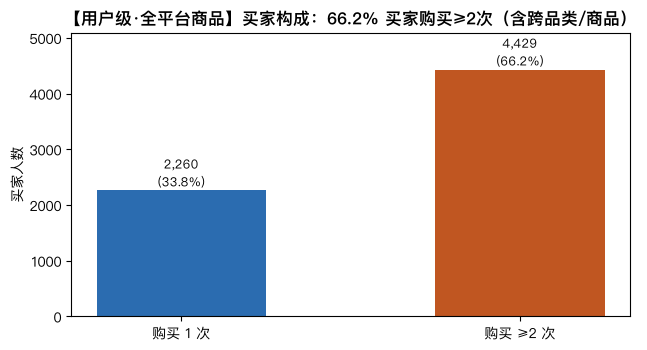

In [38]:
plot_buyer_segmentation(pre_purchase)

**购买事件构成解读：**

- 事件口径：20,359 = 首购 6,689（32.9%）+ 同品复购 1,020（5.0%）+ 换品复购 12,650（62.1%）。
- 人头口径：首购数 6,689 = 样本内全部买家数 6,689 人；其中 33.8%（2,260 人）只买了 1 次，66.2%（4,429 人）购买 ≥2 次。两图交叉验证


**核心结论**
1. **大盘靠复购买家**：4,429 名复购买家总共贡献 13,670 次复购事件（占事件总量 67.1%），人均约买 4.1 单；一次性买家仅贡献 2,260 单。少数高频买家是成交主体。
2. **复购几乎全是"换品"**：换品 : 同品 ≈ 12 : 1 → 用户回来是买"新东西"，不是补货同款。这是典型的**多样性寻购**平台，而非消耗品补货型平台。
3. **首购仍占 1/3**，新客转化通道持续有效，增长飞轮未纯靠存量用户空转。

**业务含义**
- 核心杠杆是**交叉销售 / 推荐系统**（跨品类关联、新品曝光），而非补货提醒、订阅购买，因为同品复购仅 5%。
- 2,260 名一次性买家（33.8%）是"二单转化"蓄水池，应作为新客培育（首单后优惠券、召回 push）的优先人群。

**严谨性提示**
- "首购"是**窗口内**首购，非平台真实新客；观察窗仅 ~9 天而复购率高达 66.2%，样本明显富集活跃用户，外推全平台需谨慎。
- 不区分商品 ID 的换品复购混合了"同类目深化"与"跨类目迁移"，若要精细运营，需下钻类目级复购矩阵。

### 4.2 单商品的购买前行为路径模式分类
**分析目标**： 买**这件**商品的人，买前走了什么路径? 识别用户购买前最常见的几种行为路径模式（如：pv→buy、pv→fav→buy、pv→cart→buy、pv→fav→cart→buy等），并统计各路径的占比。

注：我们只看下单的某件商品，与该商品有关的前置行为路径，与 4.1的概念要区别开，不要混淆

总购买事件数：20,359
去重路径模式数：40
含收藏(fav)环节路径占比：6.5%
不含收藏环节路径占比：93.5%

TOP 15 路径模式：
 1. （空）                     8,103  ( 39.8%)
 2. pv                      7,460  ( 36.6%)
 3. cart→pv                 1,432  (  7.0%)
 4. cart                    1,215  (  6.0%)
 5. fav→pv                    513  (  2.5%)
 6. pv→cart→pv                422  (  2.1%)
 7. fav                       411  (  2.0%)
 8. pv→cart                   305  (  1.5%)
 9. pv→fav→pv                 136  (  0.7%)
10. pv→fav                    100  (  0.5%)
11. cart→pv→cart→pv            46  (  0.2%)
12. fav→cart→pv                27  (  0.1%)
13. cart→pv→cart               27  (  0.1%)
14. fav→pv→cart→pv             24  (  0.1%)
15. fav→cart                   22  (  0.1%)


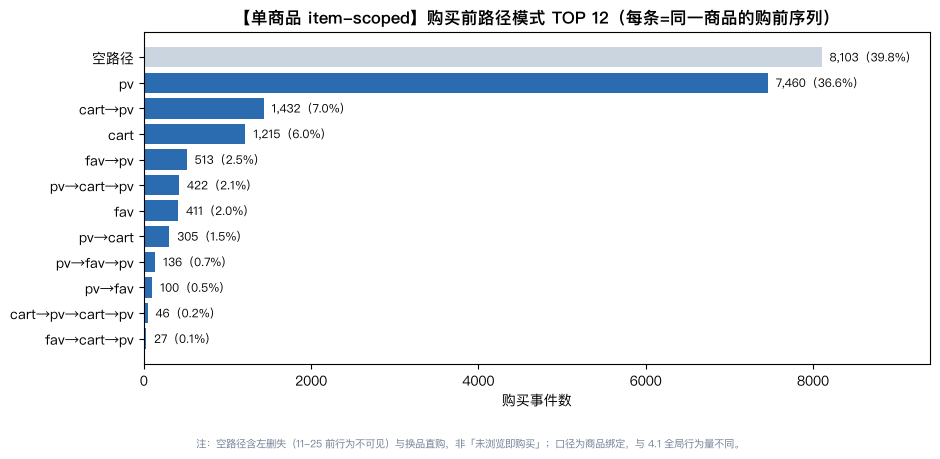

In [39]:
# 单品类购前路径
paths = extract_pre_purchase_paths(df)
counts, total = summarize_paths(paths, topn=15)
plot_top_path_patterns(counts, total, topn=12)


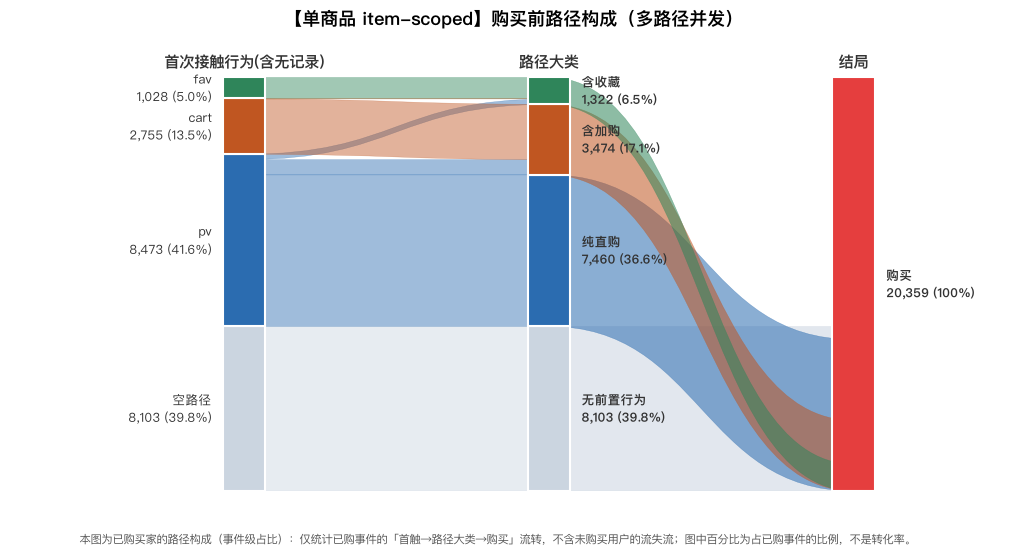

In [40]:
# 4.2 补充可视化：购买前路径构成桑基图（事件级占比）
# 实现已抽取至 src/ecommerce_conversion_analysis/pre_purchase.py::plot_pre_purchase_sankey
plot_pre_purchase_sankey(paths)


**分析口径**
- 商品绑定（item-scoped）：仅观察每次购买**所属商品在「该次购买之前」的行为序列**；pv/fav/cart 其它商品不计入。
- 折叠连续重复行为、去重为有序阶段（如 `pv,pv,cart` → `pv→cart`）；
- 计数单位：以「购买事件」计（共 20,359 次），与 4.1 一致；
- 本分析为描述性占比，非转化率（4.2 仅含已购序列，无未购对照）。

**核心发现**
全量购买去重得 40 种路径模式，TOP5 覆盖 91.9%：
- （空）39.8% —— 该商品购买前无任何 pv/fav/cart 记录
- pv 36.6% —— 仅浏览后即购买
- cart→pv 7.0% —— 加购后回看、再购买
- cart 6.0% —— 加购后即购买
- fav→pv 2.5% —— 收藏后回看、再购买

含收藏(fav)环节的路径仅占 6.5%、不含达 93.5%——收藏功能在转化链中参与度极低。

**口径边界**
- **约 83% 的购买不经过加购：标准漏斗「浏览→加购→购买」并非主流**，多数购买为「看后即买」或窗口内无前缀。
- 空路径 39.8% 是混合桶：含左删失（11/25 前浏览不可见）与换品复购（老客直接再买），不能解读为"用户未浏览即购买"。
- 「cart 打头」≠"未浏览即加购"：序列是 item 维度 + 9 天跨会话折叠后的投影。经推荐位对展示了 A，于是顺手把商品 A 加购了，于是A 维度会呈现 cart 在前，真实浏览发生在 B 而被维度切离。路径"顺序"不等于用户单次会话的线性漏斗。
- "含加购"口径 = 路径含 cart 但不含 fav；"含收藏" = 路径至少 1 次 fav（cart 在不在都算）。同一购买事件两桶互斥，按 fav 优先于 cart 的规则判定。"路径里加过购的总人数"需另算（含 fav 的 cart 事件不在"含加购"桶内）。
- 本节「空路径 39.8% + 仅浏览 36.6% = **76.4%**」是**事件级**口径——以每条购买事件为单位，看其路径是否经过 cart/fav。 76.4% 说明"多数单次购买**事件**不经过 cart/fav"。


**业务含义**
**cart/fav 是"偶尔使用的辅助通道"**，既不是"每次必经"，也不是"绝大多数人不用"。
加购、收藏均非转化必经环节，直购与纯浏览转化是主流；优化重点应放在详情页浏览→直接转化路径，而非过度依赖购物车/收藏召回。


### 4.3 不同品类的购买前行为路径差异分析 <br>
**分析目标：** 不同品类的购前路径结构是否不同？(沿用 4.2 的路径定义, 仅额外按品类分组)

Top 20 品类（按购买事件数）路径结构摘要：
 category_id  n_buy  empty_rate  pv_only_rate  cart_rate  fav_rate  avg_stages dominant_path
     2735466    363       36.64         37.47      18.46      7.44        0.87            pv
     1464116    352       43.18         38.07      12.22      6.53        0.72           （空）
     4145813    326       23.62         40.80      27.30      8.28        1.14            pv
     2885642    310       47.10         35.16      10.32      7.42        0.64           （空）
     4801426    280       27.86         35.36      25.71     11.07        1.12            pv
     4756105    260       20.00         39.62      28.85     11.54        1.26            pv
      982926    237       26.16         36.71      29.96      7.17        1.11            pv
     1320293    171       27.49         41.52      21.05      9.94        1.02            pv
     2640118    170       31.76         41.18      22.94      4.12        0.90            pv
     3002561    168       29.76         35.12

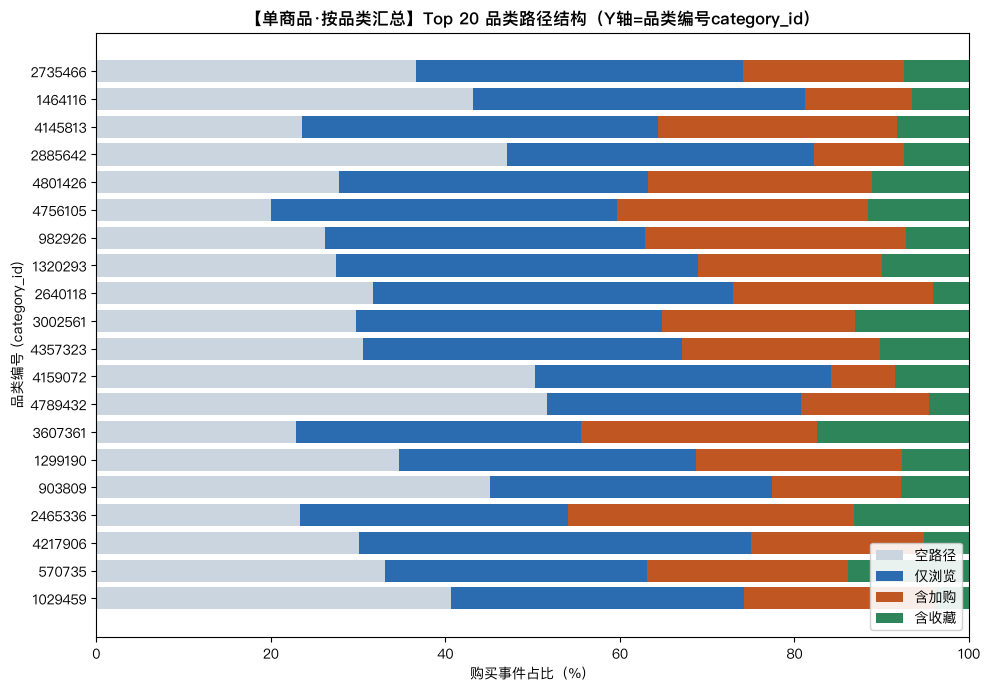

In [41]:
# 不同品类路径结构
paths_df = extract_paths_with_category(df)
summary  = build_category_summary(paths_df, top_k=TOP_K)

print(f"Top {TOP_K} 品类（按购买事件数）路径结构摘要：")
with pd.option_context('display.max_rows', TOP_K, 'display.width', 160):
    print(summary.round(2).to_string(index=False))

plot_category_buckets(summary)


**分析口径**
- 取购买事件数最高的 Top 20 品类（全量共 5793 个品类，长尾分布，Top1 也仅占约 5%）；
- **沿用 4.2 路径定义**（item-scoped 商品绑定、折叠连续重复、以购买事件计数），**仅额外按 category_id 分组**；
- 本分析为描述性占比，非转化率（转化率对比留待第五章漏斗）。

**核心发现**
Top 20 品类购买数 128–363，路径结构差异显著：
- 空路径率 20.0%–51.7%、含加购率（不含收藏）7.3%–32.9%、品类间相差 2–4.5 倍；
- 所有品类的主导路径均为「pv」或「（空）」，无一以加购/收藏为主导，印证 4.2 结论（约 83% 购买不经加购）在品类层依然成立。

**两类典型品类**
- **直接购买型**（空路径高、含加购低）：**4789432**（空 51.7% / 加购 14.6%/ 收藏 4.64%）、**4159072**（空 50.3% / 加购 7.3% / 收藏 8.48% ）、**2885642**（空 47.1% / 加购 10.32%/ 收藏 7.42%）；基本"看或啥也不看就买"，加购/收藏召回价值偏低。
- **加购培育型**（空路径低、含加购高、阶段数高）：**2465336**（空 23.4% / 加购 32.9% / 收藏 13.1%）、**4756105**（空 20.0% / 加购 28.9% / 收藏 11.54%）、**982926**（空 26.2% / 加购 30.0% / 收藏 7.17%）、**4145813**（空 23.6% / 加购 27.3% / 收藏 8.28%）；需"浏览→加购→回看"才下单，值得做加购提醒/凑单。
- **收藏驱动特例**：**3607361** 含收藏率 17.4%（全场最高，约为均值 4 倍），收藏在该品类真正起作用。

**口径边界**
- 含加购率为"含加购但不含收藏"的路径占比，真实含加购参与率略高于此（需加上同时含收藏的路径），因收藏占比小误差可忽略。
- **本分析为商品绑定（仅看该商品前缀），口径比 4.1 用户级更窄，故阶段数天然偏低。**

**业务含义**:
- 品类路径画像有实战价值：直购型品类应优化详情页→直接转化、弱化购物车依赖；加购培育型品类应强化加购提醒、凑单与比价引导；少数收藏驱动品类可测试收藏夹召回。两类运营抓手不同，不宜一刀切。


### 4.4 单商品的购买路径耗时分析（时间维度）
** 用户从首次接触到最终购买，平均需要多长时间（分钟/小时/天），不同路径模式的耗时是否存在差异。

有可观测耗时的购买事件：12,256（空路径 8,103 笔无窗口内前缀接触，已排除）
耗时中位数：1.89 小时（≈ 0.08 天）
P75：23.33 小时 ｜ P90：66.68 小时
注：右删失于 ~9 天窗口；以下为窗口内下界，非真实 time-to-purchase

TOP 15 路径模式的可观测耗时（中位数，小时）：
  pv                     n=  7460  median=0.46h
  cart→pv                n=  1432  median=23.71h
  cart                   n=  1215  median=14.15h
  fav→pv                 n=   513  median=8.71h
  pv→cart→pv             n=   422  median=30.23h
  fav                    n=   411  median=0.26h
  pv→cart                n=   305  median=19.77h
  pv→fav→pv              n=   136  median=14.31h
  pv→fav                 n=   100  median=2.09h
  cart→pv→cart→pv        n=    46  median=45.58h
  cart→pv→cart           n=    27  median=45.95h
  fav→cart→pv            n=    27  median=27.38h
  fav→pv→cart→pv         n=    24  median=24.11h
  fav→cart               n=    22  median=22.48h
  fav→pv→cart            n=    22  median=9.96h


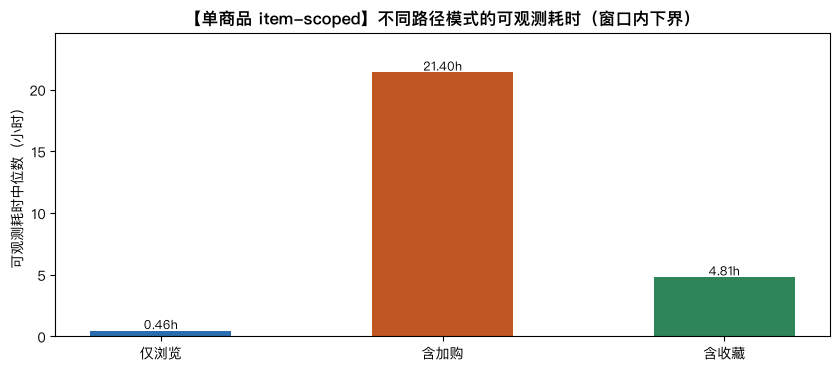

In [42]:
# 4.4 不同路径模式耗时
paths_dur = extract_paths_with_duration(df)
d_with_dur = summarize_duration(paths_dur, topn=15)
plot_duration_by_bucket(paths_dur)

**分析口径**
- 空路径（窗口内无任何前行为事件接触）共 8,103 笔，因为无法计算耗时，已排除；仅对 12,256 笔有可观测耗时的购买事件统计；
- 关键限制：左删失（11/25 前首次接触不可见）→ 测得为「窗口内可观测耗时（下界）」，非真实 time-to-purchase。

**核心发现**
有可观测耗时的购买事件中位数 1.89 小时（≈0.08 天），P75 23.33 小时、P90 66.68 小时（≈2.78 天，远低于 9 天窗口，故中心趋势可信，仅极端尾部受封顶影响）。路径模式间耗时差异极大：
- 冲动型：纯 pv 中位 0.46 小时、纯 fav 0.26 小时（全场最快）；
- 深思型：cart 14.15 小时、cart→pv 23.71 小时、pv→cart→pv 30.23 小时、cart→pv→cart→pv 45.58 小时；
- cart→pv 中位耗时约为纯 pv 的 51 倍，且「加购往返越多越久」呈单调上升（pv→cart 19.77h < pv→cart→pv 30.23h < cart→pv→cart→pv 45.58h）。

**口径边界**
- 首次接触受左删失截断：用户在 11/25 前就浏览过的商品，其真实耗时被低估为窗口内下界；相对差异（模式间 / 品类间高低）仍有效，删失对所有组一视同仁。

**收藏的反直觉特例**
纯 fav（收藏即买）中位 0.26 小时，比 pv 还快；但只要 fav 后还带其他行为（fav→pv 8.71h、fav→cart 22.48h），耗时立刻拉长。故「收藏」本身不是深思信号，收藏＋后续浏览 / 加购才是。

**业务含义**
快路径（纯 pv / 纯 fav）≈低考虑度冲动购买，应优化详情页→一键转化的摩擦、少加多余步骤；慢 cart 路径≈高考虑度犹豫购买，应用购物车提醒、降价预警、比价辅助去「接住」这批用户，而非催促立即下单。两类运营抓手完全不同。


## 五. 全平台用户行为渗透与流转分析 (转化漏斗)

### 5.1 (A) 设计思路

前面的 **4.1~4.4 章节**，我们分别从“购买事件”“商品”“品类”等角度，分析了用户的购买前行为路径。这些分析回答的核心问题是：

> **“一个购买行为发生之前，用户都经历了哪些步骤？”**

这些分析非常有用，但它们有一个共同特点：**分母是“行为”或“商品”，而不是“用户”**。具体来说：

| 章节 | 分析单位 | 分母是什么？ | 回答的问题                                    |
| :--- | :--- | :--- |:----------------------------------------------|
| 4.1 | 购买事件 | 20,359 个购买事件 | 每一次购买前，用户经历了什么？                |
| 4.2 | 商品 | 每个商品的购买事件 | 买这个商品的人，走了什么路径？                |
| 4.3 | 品类 | 每个品类的购买事件 | 不同品类的路径模式有什么差异？(是 4.2 的聚合) |
| 4.4 | 商品 | 每个商品的购买事件 | 不同路径模式耗时多久？                        |

这些分析有一个共同的“盲区”：**它们只看“已经购买的人/事件”，没有回答一个更宏观的问题——**

> **“在整个平台上，所有来过的人里，有多少人最终买了？没买的人，他们走到了哪一步就流失了？”**

举个例子：4.2 分析了“PV→Cart”这条路径上的用户行为，然后计算出它的总路径占比是1.5%. 但你不知道的是：**有多少人“Pv→Cart”之后，并没有走到“购买”这一步，而是流失了？** 这些人是谁？他们占比多大？

另外，在4.2章节中，我们也得知了用户购买一件商品，在去重之后有40种不同的路径模式, 它的路径其实是很复杂的。所以如果我们按照标准的、有序的漏斗（PV→Fav/Cart→Buy）作为转化分析的方式，其实会漏掉很多行为信息.

这个问题，**只有切换到“以用户为分母”的视角才能回答**。

因此，**第五章的核心任务，就是把分析视角从“行为事件”切换到“活跃用户”**，从宏观到微观，回答三个层面的问题：

1. **渗透层**：来到平台的用户，分别有多大比例产生了PV、Fav、Cart、Buy行为？
2. **分层层**：用户的行为深度是如何分布的？只看不买的有多少？加购后成交的有多少？
3. **流转层**：某个行为（如cart）最终带来了多少成交？哪个环节流失最严重？

注：窗口内**未观测到购买 ≠ 已流失（右删失）**"——9 天窗口内的"仅浏览/收藏/加购"三组是"未观测到购买"，不能完全定义为"永久流失"。

### 5.1(B) 设计口径

第 5 章从全平台用户的视角，评估用户在9天内的行为转化效率。与传统的“单商品漏斗”不同，本章节分析关注的是用户行为深度而非商品转化路径。通过拆解用户从“浏览”到“购买”的行为渗透与流转，定位平台运营的关键优化环节。

**核心口径说明：**

- 分析单位：用户（去重），而非行为次数。同一用户多次相同行为只计1次
- 行为类型：PV（浏览）、Fav（收藏）、Cart（加购）、Buy（购买）
- 总活跃用户：统计周期内，有过 PV / Fav / Cart / Buy 中任意一种行为的去重用户总数
- 5.2 的渗透率不要求(pv,fav,cart,buy)顺序，只要用户发上过以上一种行为，就会在去重后计入统计；**注意，不管同一个用户有过几次pv, 在pv的计数上都是 +1； fav, cart, buy的统计上同理。**
- 5.4 流转分析要求顺序，比如 P(buy|cart) 中的 buy **一定要发生在用户** cart **之后**；P(buy|fav) 和  P(buy|pv)也是同理。另外，我们在做流转分析的时候，**不需要限定以上行为必须发生在是同一件商品**。 我们 5.3 要做的是分析并了解用户的行为习惯，而不是商品的转化效率。我们需要了解 pv 或者 cart 又或者 fav 行为是否让用户更倾向于在平台下单，而不是某个商品被加购之后有多少最终被卖掉了。

### 5.2 用户行为渗透率（并行漏斗）

**目标**

“来到平台的用户，分别有多大比例产生了各类行为？” 这是一个宏观的用户质量概览，能帮助快速判断平台用户是“随便逛逛”为主，还是“有明确购买意向”为主。

**口径说明：**

- 分别统计有过 PV、Fav、Cart、Buy 行为的去重用户数
- 四个指标相互独立、并行计算，不要求用户按 PV→Fav→Cart→Buy 的顺序发生
- 分母统一为 总活跃用户数

**计算公式：**

- PV渗透率 = 有过PV的用户数 / 总活跃用户数 × 100%
- Fav渗透率 = 有过Fav的用户数 / 总活跃用户数 × 100%
- Cart渗透率 = 有过Cart的用户数 / 总活跃用户数 × 100%
- Buy渗透率 = 有过Buy的用户数 / 总活跃用户数 × 100%

In [43]:
# 5.2 用户行为渗透率（并行漏斗）
# 实现已抽取至 src/ecommerce_conversion_analysis/user_funnel.py
penetration, total_users = compute_behavior_penetration(df)
print(f"分母 · 全平台总活跃用户数：{total_users:,} 人")
print(tabulate(penetration, headers='keys', tablefmt='pretty', showindex=False))

分母 · 全平台总活跃用户数：9,739 人
+------+------------+-----------+
| 行为 | 去重用户数 | 渗透率(%) |
+------+------------+-----------+
|  pv  |    9706    |   99.66   |
| fav  |    3882    |   39.86   |
| cart |    7323    |   75.19   |
| buy  |    6689    |   68.68   |
+------+------------+-----------+


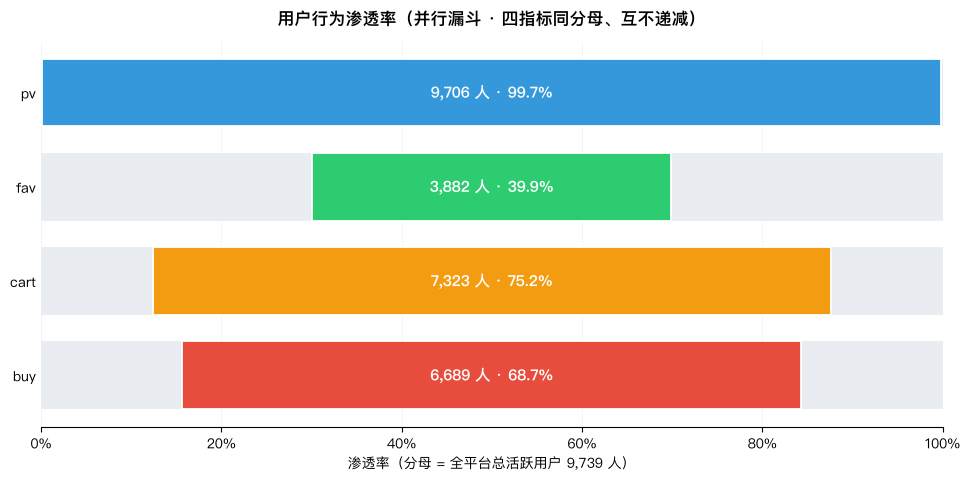

In [44]:
# 5.2 可视化：并行漏斗（100% 灰底槽 + 居中条带）
plot_behavior_penetration(penetration, total_users, color_map)

- **加购渗透率 75.2% 高于购买渗透率 68.7%**——加过购的人数比最终买的人还多，说明在本数据集里加购更像「囤货/比价」而非「购买意向」；
- **浏览渗透率 99.7% 几乎全员**，几乎没有区分度，不能用作用户质量分层（这也埋了 5.4 章节的一个坑：未浏览用户仅 33 人，对照组样本不足）；
- **收藏渗透率仅 39.9%**，是四类行为中最低的，说明收藏是低承诺行为（与 4.2 章节「购买前路径含 fav 仅 6.5%」一致）。

### 5.3 用户行为组合分布

**目标**

5.2 告诉我们“有多少用户做过某类行为”，但没有告诉我们用户的行为深度组合。比如：一个“有过Fav”的用户，他可能同时也Buy了 ，也可能只是Fav了但没Buy。分析通过互斥分组，把用户按“最深行为”分类，回答：“平台用户中，只看不买的有多少？”

**口径说明**

- 将每个用户按照其在9天内达到的最深行为归入唯一分组（互斥）
- 分组逻辑（按优先级从高到低): **Buy (购买用户) > Cart（加购用户） > Fav（收藏用户） > PV（仅浏览用户）**
- 四组用户数之和 = 总活跃用户数
- 各组占比 = 该组用户数 / 总活跃用户数 × 100%
- 购买用户：有过 Buy → 封顶了，直接归入此类（无论有没有 PV/Fav/Cart）
- 加购用户：没有 Buy，但有过 Cart → 归入此类（无论有没有 PV/Fav）
- 收藏用户：没有 Buy，没有 Cart，但有过 Fav → 归入此类（无论有没有 PV）
- 仅浏览用户：只有 PV，其他什么都没有 → 归入此类

**和第 4 章的口径区分**

- 第四章是按购买的行为事件计数，一个用户购买 N 次，那就算 N 次购买事件。然而，第五章是以用户行为深度作为转化分析，不管用户是只购买了一次，还是购买了 N 次，**只要产生了至少一次购买的行为，那就归入“购买用户” +1**。 “购买用户”不再往下细分。（不区分“买一次”和“买多次”），这个区分我已经在 4.1 首购/复购分析里做过了。

In [45]:
# 5.3 用户行为组合分布（互斥分组 · Buy 封顶）
# 实现已抽取至 src/ecommerce_conversion_analysis/user_funnel.py
# 函数内含 assert：四组之和必须等于总活跃用户数
combo, total_users = compute_behavior_combination(df)
print(tabulate(combo, headers='keys', tablefmt='pretty', showindex=False))

+---------------+--------+---------+
|   用户分组    | 用户数 | 占比(%) |
+---------------+--------+---------+
| 购买用户 Buy  |  6689  |  68.68  |
| 加购用户 Cart |  2021  |  20.75  |
| 收藏用户 Fav  |  462   |  4.74   |
| 仅浏览用户 PV |  567   |  5.82   |
+---------------+--------+---------+


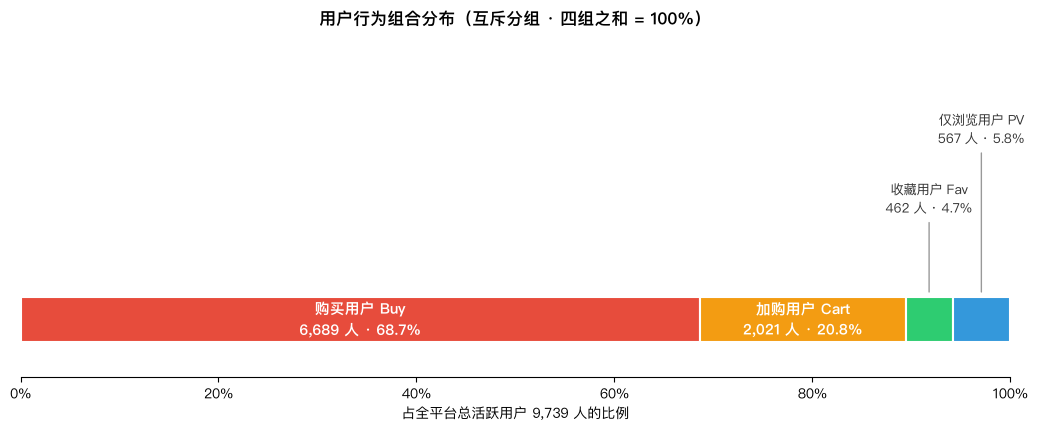

In [46]:
# 5.3 可视化：100% 横向堆叠条（互斥构成，四组刚好填满）
plot_behavior_combination(combo, total_users, color_map)

- **9,739 名活跃用户按「最深行为」互斥分组**（Buy 封顶：有 Buy 一律归 Buy 组，其余按 Cart→Fav→PV 降级）：购买用户 **6,689（68.7%）**、加购用户 **2,021（20.8%）**、收藏用户 **462（4.7%）**、仅浏览用户 **567（5.8%）**，四组填满 100%。

- **与 5.2 的关键区别：5.2 看「用户做过什么」（非互斥、可叠加）、5.3 看「最深做到哪一步」（互斥填满）**。表面看 5.2 的 buy 渗透率 68.7% 和 5.3 的购买用户 68.7% 数字相同，但本质不同——前者是「至少买过一次的人占总活跃人数的百分比」，后者是「按最深行为分类时这群人被归到 Buy 组」（Buy 封顶使两组人数碰巧一致）。**真正差异最大的对照**：5.2 的 PV 渗透率 99.7% 包含了「买过的人也浏览过」，5.3 的「仅浏览」5.8% 才是「除了浏览其他什么也没做」——近 94 个百分点的差距就是「深度可叠加」与「互斥构成」的根本区别，所以不能把这两条蓝色 PV 数字混为一谈。

- **业务洞察**：加购但未购买的 **2,021 人（20.8%）** 是平台最大的未转化池——他们已主动加购（高购买意图），却在 9 天窗口内未完成下单，是后续运营最值得召回的对象。


### 5.4 用户行为流转分析

**目标**

5.2 和 5.3 告诉我们“用户做了什么”，但没有告诉我们“某个行为最终带来了多少成交”。本分析通过计算条件概率，回答三个关键业务问题：

- P(Buy | Cart)： 加购的转化效率如何？ → 加购的人里，有多大比例最终买了？
- P(Buy | Fav) ： 收藏的转化效率如何？ → 收藏的人里，有多大比例最终买了？
- P(Buy | PV)：  浏览的转化效率如何？ → 浏览的人里，有多大比例最终买了？

**口径说明**

- 三个流转率**严格遵循时间顺序**：Buy 行为必须发生在 PV / Fav / Cart 行为之后。
- 分子必须是“先有前置行为、后有购买”的去重用户数。
- 不需要限定以上行为必须发生在是同一件商品。
- 每个流转率均补充对照基准，用于评估该行为的增量贡献：
  - `P(Buy | 未加购)` 作为 `P(Buy | Cart)` 的对照组
  - `P(Buy | 未收藏)` 作为 `P(Buy | Fav)` 的对照组
  - `P(Buy | 未浏览)` 作为 `P(Buy | PV)` 的对照组
- 全平台购买渗透率（68.7%，即 6,689 / 9,739）作为整体基准线
- 计算 **Lift（提升度）** = 流转率 / 对照基准率，Lift > 1 表示该行为对购买有正向促进作用(越大越好）; Lift = 1：表示加购对购买没有影响；Lift < 1：加购反而抑制了购买（不太可能出现）

**计算公式**

| 流转率 | 公式 | 数学记号 | 对照组 | Lift |
| :--- | :--- | :--- | :--- | :--- |
| **加购→购买** | 先Cart后Buy的用户数 / 有过Cart的用户数 | P(Buy \| Cart) | P(Buy \| 未加购) | P(Buy\|Cart) / P(Buy\|未加购) |
| **收藏→购买** | 先Fav后Buy的用户数 / 有过Fav的用户数 | P(Buy \| Fav) | P(Buy \| 未收藏) | P(Buy\|Fav) / P(Buy\|未收藏) |
| **浏览→购买** | 先PV后Buy的用户数 / 有过PV的用户数 | P(Buy \| PV) | P(Buy \| 未浏览) | P(Buy\|PV) / P(Buy\|未浏览) |

**⚠️ 重要区分**

`P(Buy | Cart)` 与 `P(Cart | Buy)` 是不同指标，含义完全不同：

- `P(Buy | Cart)` = 加购用户的购买转化率（衡量**加购这个环节的效率**）
- `P(Cart | Buy)` = 购买用户中提前加购的占比（描述**购买用户的行为特征**）

本分析统一使用前者（条件概率方向为 **前置行为 → 购买**）。

In [47]:
# 5.4 用户行为流转分析（有序流转率 + 对照组 + Lift）
# 实现已抽取至 src/ecommerce_conversion_analysis/user_funnel.py
flow, baseline = compute_behavior_conversion(df)
print(f"全平台购买渗透率基准线：{baseline:.2f}%")
print(tabulate(flow, headers='keys', tablefmt='pretty', showindex=False))

全平台购买渗透率基准线：68.68%
+------+----------+----------+-----------+----------+-----------+-------+----------------+
| 行为 | 暴露人数 | 流转人数 | 流转率(%) | 对照人数 | 对照率(%) | Lift  |   对照组可信   |
+------+----------+----------+-----------+----------+-----------+-------+----------------+
| 加购 |   7323   |   4693   |   64.09   |   2416   |   57.41   | 1.116 |       ✓        |
| 收藏 |   3882   |   2320   |   59.76   |   5857   |   66.6    | 0.897 |       ✓        |
| 浏览 |   9706   |   6573   |   67.72   |    33    |   81.82   | 0.828 | 样本不足(n=33) |
+------+----------+----------+-----------+----------+-----------+-------+----------------+


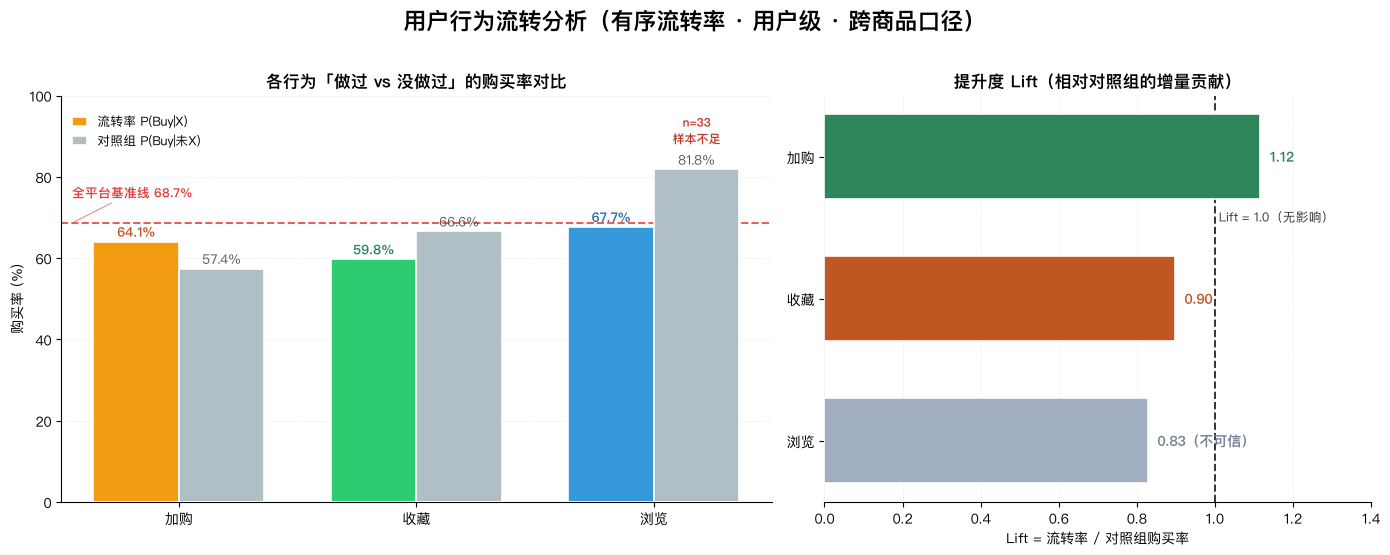

In [48]:
# 5.4 可视化：左 = 绝对水平对比（含基准线）/ 右 = Lift 提升度
plot_behavior_conversion(flow, baseline, color_map=color_map)

- **加购是唯一对购买有正向关联的行为**：加购用户流转率 **64.09%**（4,693 / 7,323），对照组（从未加购）整体购买率 57.41%，**Lift = 1.12**——加购者的购买率比未加购者高约 12%, 也是三类行为中唯一 Lift > 1 的。**但这是观察性关联、非因果效应**：加购是用户自选行为，两组人群存在固有差异（选择偏差），不能解读为「加购动作带来了 12% 的增量」；

- **收藏的 Lift 为 0.90（< 1）**：收藏用户流转率 59.76%，反而低于未收藏用户的 66.60%。结合 4.2 章节「购买前路径含 fav 仅 6.5%」，说明收藏在本数据集更多是**低承诺的「种草 / 观望」动作**，而非购买前奏——收藏量大不等于购买意向强。

- **浏览一组不可解读**：对照组仅 **33 人**（99.66% 的用户都有 pv，几乎无人「未浏览」），Lift 0.83 不具统计意义；这 33 人购买率 81.82% 高于大盘，系数据集起点的左删失用户（pv 发生在观测窗之前未被记录），**不可解读为「不浏览反而买得多」**。

- **与 5.2 / 5.3 的呼应**：5.2 发现加购渗透率（75.19%）反而高于购买渗透率（68.68%），5.3 进一步量化出 **2,021 名加购未购用户**；5.4 则显示加购仍是三者中最强的购买信号（Lift 1.12）。三节合起来给出一致结论——**加购是「高意向但未完成」的关键节点，这 2,021 人是最值得运营召回的对象**。

- **Lift 口径说明**：对照组 P(Buy|未X) 中「未做过 X」无从定义时间先后、无法施加时序约束，故本表 Lift 为**保守估计**。敏感性参照：若两侧均改用不分顺序口径，加购 Lift = **1.26**、收藏 Lift = **1.08**——结论方向一致，强度更高。


## 六. 购买用户分层分析 —— 基于 RFM 框架的行为价值分层

### 6.1 分析目的与口径说明

**一、本章要回答的问题**

第五章从全平台 9,739 名活跃用户的视角，回答了"多少人最终买了"——购买渗透率 68.7%，即 6,689 人完成了至少一次购买。但它没有回答下一个问题：

> 这 6,689 名买家之中，谁更值得投入运营资源？

本章用 RFM 框架对买家做分层，把"都发生过购买"的一群人拆成投入产出特征不同的几组，为精细化运营提供对象清单。

**二、分析对象与边界**

| 人群 | 人数 | 占比 | 本章处理 |
| :--- | ---: | ---: | :--- |
| 购买用户 | 6,689 | 68.7% | 进入 RFM 分层（本章主体） |
| 加购未购买 | 2,021 | 20.8% | 不进 RFM，见 6.7 |
| 收藏未购买 | 462 | 4.7% | 不进 RFM，见 6.7 |
| 仅浏览 | 567 | 5.8% | 不进 RFM，见 6.7 |

需要特别说明：把 RFM 限定在买家身上，**不是因为未购买的人少**——31.3% 并不小，且其中 2,021 名加购未购买者是全平台意向最强的未转化池。真正的原因是口径上的必然：R、F、M 三个指标全部定义在"已发生的购买行为"之上，没有任何购买记录的用户在三个维度上均无取值，强行置零会人为制造出一个虚假的"最低价值层"。这 3,050 名未转化用户在 6.7 节单独承接。

**三、口径定义**

| 指标 | 定义 | 计算式                                       | 方向 | 实测分布 |
| :--- | :--- |:---------------------------------------------| :--- | :--- |
| R（Recency） | 最近一次购买距分析截止日的天数 | (2017-12-04 00:00:00 − max(buy_time)) / （24 × 60 × 60） | 越小越好 | 中位 2.24 天，全距 0.001–9.0 |
| F（Frequency） | 窗口内购买次数 | count(behavior_type = 'buy')                 | 越大越好 | 中位 2、均值 3.04，全距 1–72 |
| M_item | 购买过的去重商品数 | nunique(item_id)，仅 buy                     | 越大越好 | 中位 2、均值 2.89，全距 1–66 |
| M_cat | 购买过的去重品类数 | nunique(category_id)，仅 buy                 | 越大越好 | 中位 2、均值 2.65，全距 1–58 |
| buy_days | 有购买行为的去重天数 | nunique(date)，仅 buy                        | 越大越好 | 中位 2，全距 1–9 |
| pv_cnt | 窗口内浏览次数 | count(behavior_type = 'pv')                  | 中性 | 中位 76，全距 0–649 |

主辅指标设定：F 以**购买次数**为主指标、**购买活跃天数**为稳健性参照（9 天窗口下同日多次购买会虚高频次）；M 以**去重商品数**为主指标、**去重品类数**为敏感性验证（避免把"同品类深买"和"跨品类广买"混为一谈）。

**四、关于 M 的重要声明**

本数据集**不包含商品价格、订单金额或支付金额字段**（数据集仅含用户与商品之间的交互行为，不含商品属性信息）。

因此本章的 M **不是 Monetary（消费金额），而是商品广度的代理指标**。严格来说，本章构建的是 R-F-B（Recency-Frequency-Breadth）模型；考虑到 RFM 是行业通用称谓，本章沿用 RFM 命名，但所有涉及"价值"的表述均指**行为价值**，不涉及金额、ARPU 或客单价。

**五、本章不做的事**

1. **不做流失预测**：观测窗口仅 9 天，且无窗口之后的行为可供验证。任何"流失""预警"标签都只是待验证假设，本章一律改用描述性命名（如"窗口早期购买后未复现"）。
2. **不做金额相关推断**：数据无价格字段，不计算 ARPU、客单价、GMV 贡献。
3. **不给因果结论**：分层是描述性的，6.6 节以"可验证假设 + holdout 设计"形式给出，不以"策略有效"的口吻下结论。

**六、与前后章节的口径边界**

- 与 5.2 的区别：5.2 的渗透率是**去重人数**口径（一人计 1 次），本章 pv_cnt 是**行为次数**口径（一人可计多次），两者不可互相引用。
- 与 1.3 的关系：pv_cnt 直接复用 `src/ecommerce_conversion_analysis/eda.py::build_user_profile` 已产出的 `n_pv`，不重复计算。
- 与第四章的衔接：第四章已证明换品复购与同品复购之比约为 12:1（多样性寻购平台），本章的"购买广度"指标因此具有额外的解释价值。


### 6.2 RFM 基础指标计算

In [49]:
# 6.2 RFM 基础指标计算（实现已抽取至 src/ecommerce_conversion_analysis/rfm.py）
# 口径见 6.1：R = 最近购买距截止日的天数（浮点，保留日内精度）
#             F = 购买次数，M_item / M_cat = 购买去重商品/品类数
# 注：除 pv_cnt 外，所有指标仅统计 behavior_type == 'buy' 的记录

rfm = build_buyer_rfm(df)
print(f"买家数：{len(rfm):,} 人")
rfm.head()


买家数：6,689 人


,last_buy,Recency_days,Frequency,buy_days,M_item,M_cat,pv_cnt
user_id,,,,,,,
100,2017-11-28 09:51:17,5.589387,8,3,8,8,84.0
117,2017-11-28 16:09:39,5.326632,10,4,10,5,156.0
119,2017-11-29 20:43:31,4.136447,3,2,3,3,141.0
121,2017-11-25 22:17:35,8.071123,1,1,1,1,99.0
122,2017-12-02 13:59:07,1.417280,3,3,3,3,243.0


In [50]:
# 6.2 分布总览
print("六个指标的集中趋势与离散度")
rfm[['Recency_days', 'Frequency', 'buy_days', 'M_item', 'M_cat', 'pv_cnt']] \
    .describe(percentiles=[.25, .5, .75, .9, .95]).round(2)

六个指标的集中趋势与离散度


,Recency_days,Frequency,buy_days,M_item,M_cat,pv_cnt
count,6689.00,6689.00,6689.00,6689.00,6689.00,6689.00
mean,2.88,3.04,1.99,2.89,2.65,100.63
std,2.41,3.25,1.22,2.92,2.53,85.47
min,0.00,1.00,1.00,1.00,1.00,0.00
25%,0.69,1.00,1.00,1.00,1.00,39.00
50%,2.24,2.00,2.00,2.00,2.00,76.00
75%,4.47,4.00,3.00,4.00,3.00,137.00
90%,6.60,6.00,4.00,6.00,5.00,217.00
95%,7.53,8.00,4.00,7.00,7.00,273.00
max,9.00,72.00,9.00,66.00,58.00,649.00


In [51]:
# 6.2 校验：与第四章 / 第五章的既有数字对齐，任一 FAIL 都要停下来查
n_buy_events = int((df['behavior_type'] == 'buy').sum())

checks = {
    '① 行数 = 购买用户数 6,689': len(rfm) == 6689,
    '② Recency_days 全部落在 (0, 9]': bool(
        (rfm['Recency_days'] > 0).all() and (rfm['Recency_days'] <= 9).all()),
    '③ Frequency 求和 = 购买事件总数': int(rfm['Frequency'].sum()) == n_buy_events,
    '④ pv_cnt 无缺失（缺失已填 0）': int(rfm['pv_cnt'].isna().sum()) == 0,
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\n购买事件总数 = {n_buy_events:,}（应与第四章的 20,359 一致）")
print(f"pv_cnt = 0 的买家 = {int((rfm['pv_cnt'] == 0).sum())} 人（买过但窗口内无浏览记录）")


PASS  ① 行数 = 购买用户数 6,689
PASS  ② Recency_days 全部落在 (0, 9]
PASS  ③ Frequency 求和 = 购买事件总数
PASS  ④ pv_cnt 无缺失（缺失已填 0）

购买事件总数 = 20,359（应与第四章的 20,359 一致）
pv_cnt = 0 的买家 = 27 人（买过但窗口内无浏览记录）


> 本节完成买家级指标构建与一致性校验。各指标的分布形态与维度间关系，分别在 6.3（维度诊断）与 6.5（各层画像）中以图形呈现。

### 6.3 基于 RFM 框架的维度诊断 - R / F / M 是否相互独立

In [52]:
# 6.3 维度诊断（一）：指标间相关系数矩阵（实现已抽至 rfm.py）
# 用 Spearman 秩相关而非 Pearson：F / M_item / M_cat / buy_days 均为
# 离散计数且严重右偏，不满足 Pearson 的线性与双正态假设

corr_spearman, corr_pearson = compute_dimension_correlations(rfm)

print('Spearman 秩相关矩阵：')
print(corr_spearman.round(3).to_string())
print('\nPearson 相关矩阵（对照，验证结论不依赖相关系数的选择）：')
print(corr_pearson.round(3).to_string())


Spearman 秩相关矩阵：
              Recency_days  Frequency  buy_days  M_item  M_cat  pv_cnt
Recency_days         1.000     -0.347    -0.412  -0.349 -0.353   0.005
Frequency           -0.347      1.000     0.842   0.985  0.952   0.252
buy_days            -0.412      0.842     1.000   0.839  0.844   0.204
M_item              -0.349      0.985     0.839   1.000  0.967   0.251
M_cat               -0.353      0.952     0.844   0.967  1.000   0.246
pv_cnt               0.005      0.252     0.204   0.251  0.246   1.000

Pearson 相关矩阵（对照，验证结论不依赖相关系数的选择）：
              Recency_days  Frequency  buy_days  M_item  M_cat  pv_cnt
Recency_days         1.000     -0.258    -0.397  -0.268 -0.276  -0.006
Frequency           -0.258      1.000     0.715   0.979  0.945   0.186
buy_days            -0.397      0.715     1.000   0.727  0.746   0.183
M_item              -0.268      0.979     0.727   1.000  0.973   0.188
M_cat               -0.276      0.945     0.746   0.973  1.000   0.188
pv_cnt              -0.006 

In [53]:
# 6.3 维度诊断（二）：维度重合度（实现已抽至 rfm.py）
# 逻辑：若两个指标在测同一件事，大量用户的两个取值会完全相同

overlap = compute_dimension_overlap(rfm)
print(f"买家总数：{len(rfm):,}\n")
print(overlap.to_string(index=False))

gap = (rfm['Frequency'] - rfm['M_item']).abs()
print(f"\n|F - M_item| 平均值：{gap.mean():.3f}")
print(f"|F - M_item| ≤ 1 的用户：{int((gap <= 1).sum()):,} 人（{(gap <= 1).mean():.1%}）")
print(f"M_item > F 的用户：{int((rfm['M_item'] > rfm['Frequency']).sum())} 人"
      "（去重商品数不可能超过购买次数，期望为 0）")


买家总数：6,689

                  指标对  相同用户数       占比
  Frequency == M_item   6039 0.902826
      M_item == M_cat   5623 0.840634
   Frequency == M_cat   5202 0.777695
   M_item == buy_days   3924 0.586635
Frequency == buy_days   3847 0.575123
  Frequency == pv_cnt      5 0.000747

|F - M_item| 平均值：0.152
|F - M_item| ≤ 1 的用户：6,521 人（97.5%）
M_item > F 的用户：0 人（去重商品数不可能超过购买次数，期望为 0）


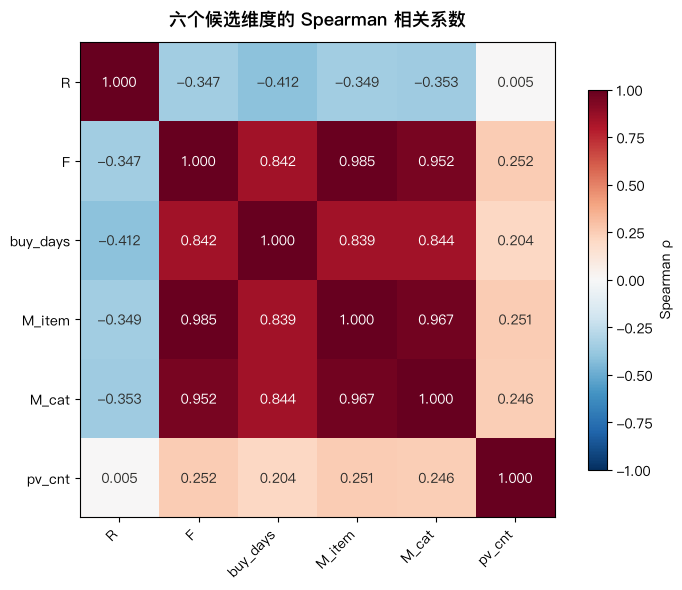

In [54]:
# 6.3 可视化：维度间 Spearman 相关系数热力图（实现已抽至 rfm.py）
plot_corr_heatmap(corr_spearman)


####  6.3 维度诊断解读

**一、相关系数矩阵**

六个候选维度的 Spearman 秩相关矩阵显示：

- **F 与 M_item 的相关系数达 0.985**，F 与 M_cat 为 0.952，M_item 与 M_cat 为 0.967——三个"购买规模"类指标彼此高度重合；
- R 与 F 为 −0.347（中等负相关：近期仍在购买的人往往买得更多），属可接受范围；
- **pv_cnt 与 R 的相关仅 0.005、与 F 为 0.252**，几乎独立于其余所有维度。

改用 Pearson 相关重算，F 与 M_item 仍达 0.979，说明结论不依赖于相关系数的选择。

**二、重合度检验**

相关系数高并不等价于指标等同，因此补做一项更直观的检验：直接统计有多少用户的两个取值完全相同。

| 指标对 | 取值相同的用户 | 占比 |
| :--- | ---: | ---: |
| F == M_item | 6,039 | **90.3%** |
| M_item == M_cat | 5,623 | 84.1% |
| F == M_cat | 5,202 | 77.8% |
| M_item == buy_days | 3,924 | 58.7% |
| F == buy_days | 3,847 | 57.5% |
| F == pv_cnt | 5 | 0.1% |

**90.3% 的买家，其"购买次数"与"购买去重商品数"是两个完全相同的数字**；两者相差不超过 1 的用户占 97.5%，平均差值仅 0.152。

**三、为什么会这样**

这不是数据错误，而是本平台购买结构的必然结果。第四章 4.1 已证明：复购事件中换品复购与同品复购之比约为 12:1，用户每次回来买的大多是新商品。因此对每个买家而言，"买 N 次"几乎必然意味着"买到 N 个不同商品"。去重商品数在数学上恒不超过购买次数（本表校验：`M_item > F` 的用户为 0 人），且二者几乎取等。

**四、维度取舍决策**

| 维度 | 处置 | 依据 |
| :--- | :--- | :--- |
| R（Recency） | **保留** | 与 F 中等相关（−0.347），携带独立的近期性信息 |
| F（Frequency） | **保留，作为购买规模主指标** | — |
| M_item | **移出分层，降为敏感性验证** | 与 F 相关系数 0.985、90.3% 取值完全相同；若同时进入分层，等于把同一变量计权两次 |
| M_cat | **降为敏感性验证** | 与 F 0.952、与 M_item 0.967 |
| buy_days | **降为稳健性参照** | 与 F 0.842 |
| pv_cnt | **升为画像维度（不参与分层）** | 与 R 仅 0.005、与 F 0.252，是唯一携带全新信息的维度 |

因此本章的分层将建立在 **R（近期性）× F（购买量）** 两个维度之上，pv_cnt 不参与分层、仅作为 6.5 节各层画像的特征指标（pv_cnt 纳入分层会产生 27 格，部分格不足 50 人）。

需要强调：移出 M 的理由**不是**"没有金额字段"（那是 6.1 节的声明），而是**即便用商品广度作为 M 的代理，它与 F 在本数据集的购买结构下，两者近乎等价**——这是一个可以在数据上证伪、且已被证伪的判断。

**五、敏感性验证安排**

M_item / M_cat / buy_days 虽不进入主分层，但将在 6.5 节用于稳健性检验：以 M_item 替换 F 重跑分层，若各层人数与画像基本不变，则证明本章结论不依赖于购买规模指标的具体选法。


### 6.4 基于 R × F 二维的用户分层与切点检验

**一、分层逻辑与为什么只用 R 和 F**

6.3 节的维度诊断得出一个关键结论：候选的六个指标并不提供六个维度的信息。

- **F（购买次数）与 M_item（购买去重商品数）高度共线**：Spearman ρ = 0.985，且 **90.3% 的买家这两个指标取值完全相同**。原因在于本平台以换品复购为主（换品 : 同品 ≈ 12:1，见 4.1），买 N 次几乎必然意味着买到 N 个不同商品。若将两者同时纳入分层，等于把同一构念计权两次。
- **M_cat 与 buy_days 同样不成立为独立维度**：M_cat 与 F 的相关系数为 0.952，buy_days 与 F 为 0.842。
- **pv_cnt 是唯一独立的候选维度**（与 R 相关 0.005、与 F 相关 0.252），但若纳入分层将产生 3 × 3 × 3 = 27 个格子，6,689 名买家摊薄后部分格子不足 50 人，无法支撑任何层级的业务结论。

因此本节的分层**建立在 R 与 F 两个维度之上**，M_item / M_cat / buy_days 退居敏感性验证角色（见 6.5），pv_cnt 作为各层的画像特征指标而非分层维度。

**二、分层规则：R 三档 × F 三档 = 9 格**

两个维度各切三档，交叉得 **9 格， 直接作为 9 层来分层使用**。

**R 档位（连续型指标）—— 按三分位数切分，再取整到整数天**

R 定义为最近一次购买距分析截止时刻（2017-12-04 00:00:00）的天数。

| 档位 | 口径 | 段位命名 | 业务含义 |
| :--- | :--- |:---------| :--- |
| 第一档 | **R ≤ 1 天** | 1 天以内     | 截止日前 1 天内仍有购买 |
| 第二档 | **1 < R ≤ 4 天** | 1–4 天    | 窗口中期仍有购买 |
| 第三档 | **R > 4 天** | 4 天以上     | 仅窗口早期有购买 |

R 是连续值（全距 0.001–9.0 天，最大并列值仅 2 人），三分位切得开、无需担心切在并列值上。原始三分位切点为 1.2161 天与 3.5458 天，取整到整数天是为了报告可读性——"R ≤ 1.22 天"无法与业务方沟通。

**F（离散型指标）—— 不使用三分位数**

F 是离散计数且高度集中：F = 1 的买家有 2,260 人（33.8%），单值即超过三分之一的样本。这导致三分位数无法使用，实测验证见本节代码输出。F 改用两条**落在数据自然边界上的切点**：

| 档位 | 口径 | 切点依据 |
| :--- | :--- | :--- |
| 第一档 | **F = 1** | 数据自然断层：F=1 是分布中最高的单值柱（33.8%），且语义上独立——"买过一次"与"复购过"是两类人，此分界与 4.1 节首购 / 复购口径一致 |
| 第二档 | **F = 2–3** | 区间填充 |
| 第三档 | **F ≥ 4** | 均值整数化：F 的均值约为 3.04，因 F 只能取整数，"≥ 3.04"在数学上等价于"≥ 4" |

这样每一档的边界都落在完整的取值上，**不会把任何一组取值相同的用户切开**。

**命名说明**：本报告的层级命名采用描述性表述——R 方向为"1 天以内 / 1–4 天 / 4 天以上"，F 方向为"单次 / 复购 / 高频复购"，组合形如"高频复购 · 4 天以上"。不使用"活跃 / 流失 / 预警 / 高价值"等标签，原因是观测窗口仅 9 天且无窗口后的行为可供验证，任何关于"流失"或"价值高低"的判断都无法在本数据集中被证实或证伪（口径声明见 6.1 第五节）。


In [55]:
# 6.4 切点依据（一）：把本节正文引用的每个切点数字打印出来，保证可追溯
n_buyers = len(rfm)

print('【R】连续型指标，按三分位数切分')
r_tercile = rfm['Recency_days'].quantile([1/3, 2/3])
print(f"    三分位第 1 刀 = {r_tercile[1/3]:.4f} 天  → 取整为 1 天")
print(f"    三分位第 2 刀 = {r_tercile[2/3]:.4f} 天  → 取整为 4 天")
print(f"    R 最大并列值人数 = {rfm['Recency_days'].round(6).value_counts().max()} 人"
      "（连续值，切得开）")
for m, lab in [((rfm['Recency_days'] <= 1),                        'R ≤ 1 天'),
               (rfm['Recency_days'].between(1, 4, inclusive='right'), '1 < R ≤ 4 天'),
               ((rfm['Recency_days'] > 4),                         'R > 4 天')]:
    print(f"    {lab:14s}: {m.sum():5,d} 人（{m.mean():5.1%}）")

print('\n【F】离散型指标，检验三分位数是否可用')
f_q3 = pd.qcut(rfm['Frequency'], 3, duplicates='drop')
print(f"    pd.qcut(F, 3) 实际切出箱数 = {f_q3.cat.categories.size}（期望 3）")
for k, v in f_q3.value_counts().sort_index().items():
    print(f"      {str(k):16s}: {v:5,d} 人（{v / n_buyers:5.1%}）")
print(f"    三分位第 1 刀应落在第 {n_buyers / 3:.0f} 人处，"
      f"而 F=1 共 {int((rfm['Frequency'] == 1).sum()):,} 人 → 落在该组内部，不可用")
print("\n    改用在数据自然边界上的切点：")
print(f"      F 均值 = {rfm['Frequency'].mean():.4f} → 整数化后等价于 F ≥ 4")
for m, lab in [((rfm['Frequency'] == 1),          'F = 1'),
               (rfm['Frequency'].between(2, 3),   'F = 2–3'),
               ((rfm['Frequency'] >= 4),          'F ≥ 4')]:
    print(f"      {lab:8s}: {m.sum():5,d} 人（{m.mean():5.1%}）")


【R】连续型指标，按三分位数切分
    三分位第 1 刀 = 1.2161 天  → 取整为 1 天
    三分位第 2 刀 = 3.5458 天  → 取整为 4 天
    R 最大并列值人数 = 2 人（连续值，切得开）
    R ≤ 1 天       : 1,759 人（26.3%）
    1 < R ≤ 4 天   : 2,832 人（42.3%）
    R > 4 天       : 2,098 人（31.4%）

【F】离散型指标，检验三分位数是否可用
    pd.qcut(F, 3) 实际切出箱数 = 2（期望 3）
      (0.999, 3.0]    : 4,875 人（72.9%）
      (3.0, 72.0]     : 1,814 人（27.1%）
    三分位第 1 刀应落在第 2230 人处，而 F=1 共 2,260 人 → 落在该组内部，不可用

    改用在数据自然边界上的切点：
      F 均值 = 3.0437 → 整数化后等价于 F ≥ 4
      F = 1   : 2,260 人（33.8%）
      F = 2–3 : 2,615 人（39.1%）
      F ≥ 4   : 1,814 人（27.1%）


In [56]:
# 6.4 分层（二）：R 三档 × F 三档 = 9 层（实现已抽至 rfm.py）
segment_buyers(rfm)

# 互斥完备校验：每位买家必须且只能落入 1 层
assert rfm['segment'].notna().all(), '存在未分层的买家'
assert len(rfm) == 6689, f'买家数异常：{len(rfm)}'
print('校验通过：6,689 名买家全部落入且仅落入一层\n')

grid = compute_segment_grid(rfm)
print('【9 层交叉表 · 人数】')
print(grid.to_string())
print('\n【9 层交叉表 · 占比 %】')
print((pd.crosstab(rfm['R_seg'], rfm['F_seg']) / len(rfm) * 100).round(1).to_string())


校验通过：6,689 名买家全部落入且仅落入一层

【9 层交叉表 · 人数】
F_seg    单次    复购  高频复购    合计
R_seg                        
1 天以内   323   700   736  1759
1–4 天   831  1158   843  2832
4 天以上  1106   757   235  2098
合计     2260  2615  1814  6689

【9 层交叉表 · 占比 %】
F_seg    单次    复购  高频复购
R_seg                  
1 天以内   4.8  10.5  11.0
1–4 天  12.4  17.3  12.6
4 天以上  16.5  11.3   3.5


In [57]:
# 6.4 切点敏感性：切点上下各挪一档，观察各档人数变化
def tier_sizes(series, bins):
    return pd.cut(series, bins=bins).value_counts().sort_index()

print('【R 切点敏感性】')
for bins, lab in [([-.01, 1, 4, 99], '原方案  R 1 / 4'),
                  ([-.01, 1, 3, 99], '下挪    R 1 / 3'),
                  ([-.01, 2, 5, 99], '上挪    R 2 / 5')]:
    s = tier_sizes(rfm['Recency_days'], bins)
    print(f"  {lab:16s}: " + " | ".join(f"{v:,} ({v/len(rfm):.1%})" for v in s))

print('\n【F 切点敏感性】')
for bins, lab in [([0, 1, 3, 10**9], '原方案  1 / 2–3 / ≥4'),
                  ([0, 1, 2, 10**9], '下挪    1 / 2 / ≥3'),
                  ([0, 2, 4, 10**9], '上挪    1–2 / 3–4 / ≥5')]:
    s = tier_sizes(rfm['Frequency'], bins)
    print(f"  {lab:20s}: " + " | ".join(f"{v:,} ({v/len(rfm):.1%})" for v in s))


【R 切点敏感性】
  原方案  R 1 / 4    : 1,759 (26.3%) | 2,832 (42.3%) | 2,098 (31.4%)
  下挪    R 1 / 3   : 1,759 (26.3%) | 2,088 (31.2%) | 2,842 (42.5%)
  上挪    R 2 / 5   : 3,036 (45.4%) | 2,162 (32.3%) | 1,491 (22.3%)

【F 切点敏感性】
  原方案  1 / 2–3 / ≥4   : 2,260 (33.8%) | 2,615 (39.1%) | 1,814 (27.1%)
  下挪    1 / 2 / ≥3    : 2,260 (33.8%) | 1,574 (23.5%) | 2,855 (42.7%)
  上挪    1–2 / 3–4 / ≥5: 3,834 (57.3%) | 1,654 (24.7%) | 1,201 (18.0%)


**各层的"绝对人数"对切点是敏感的。** 切点上下挪一格，某一档的人数会变化约 11–24 个百分点。这意味着**不能把某一组分层当成一个精确数字去分配预算**——换一套切点，这个数字会变。

**切点挪动没有打乱分层本身的结构。** 无论切点怎么挪，"单次 → 复购 → 高频复购"这个量级递增关系始终成立——因为三档本来就是按购买次数从小到大定义的，切点只决定每一档的边界落在哪、装多少人，不影响"谁比谁买得多"这个次序。



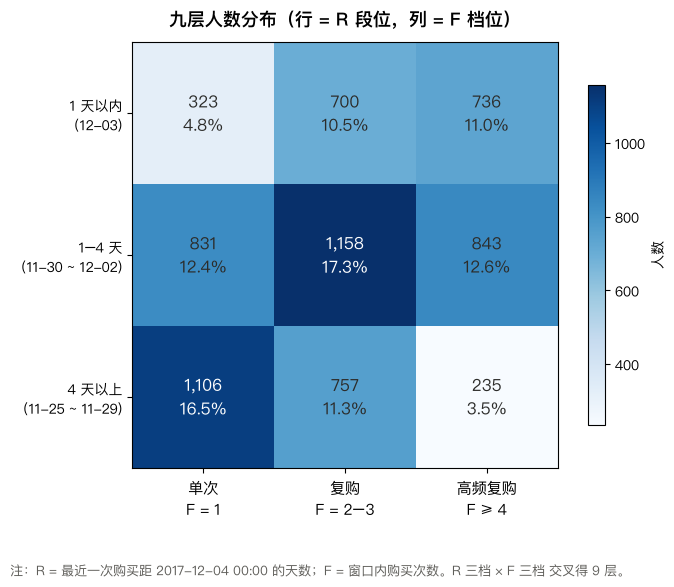

In [58]:
# 6.4 可视化：九层人数热力图（实现已抽至 rfm.py）
plot_segment_heatmap(rfm)


**九层分层结果解读**

**一、人数分布：中间厚、两端薄**

9 层人数从 235 人到 1,158 人不等。按 R 方向看，"1–4 天"三行合计 2,832 人（42.3%），是主体；"1 天以内"1,759 人（26.3%）、"4 天以上"2,098 人（31.4%）。按 F 方向看，复购（2–3 次）2,615 人（39.1%）最多，单次 2,260 人（33.8%）次之，高频复购 1,814 人（27.1%）最少。

**二、两个值得注意的结构特征（仅从交叉表即可看出）**

1. **单次层随 R 变大而递增**：单次购买者在"1 天以内"只有 323 人、"1–4 天"831 人、"4 天以上"1,106 人。越早完成首购的人越多——他们在窗口早期买过一笔后就再没回来。
2. **高频复购层集中在"1 天以内"与"1–4 天"**：高频复购买家共 1,814 人，其中 1579 人落在"1 天以内"与"1–4 天"，仅 **235 人落在"4 天以上"**。这 235 人是"买得多、却已 4 天以上没再下单"的一小群人，其画像与行为特征在 6.5 节详述。

**三、结论使用边界**

（承接上文的切点敏感性检验）本节的九层结果用于识别层间相对差异与确定运营优先级；各层**精确人数对切点敏感**（挪一格变化 11–24 个百分点），不宜直接作为资源配额。

### 6.5 各层占比、行为特征与稳健性检验

**一、本节要回答的问题**

6.4 把 6,689 名买家分成了 9 层，但只回答了"每层有多少人"。本节回答后续三个问题：

1. 每一层的人**长什么样**——买得多不多、逛得多不多、活跃几天？
2. 每一层的**浏览转化效率**如何——同样花时间逛，谁买得更多？
3. 这套分层**稳不稳**——把 F 换成 M_item 重跑，结论会不会变？

**二、指标口径**

| 指标 | 口径 | 说明 |
| :--- | :--- | :--- |
| 平均 R 天数 | 层内 `Recency_days` 均值 | 该层买家最近一次购买距截止日的平均天数 |
| 平均购买次数 | 层内 `Frequency` 均值 | — |
| 平均去重商品 / 品类 | 层内 `M_item` / `M_cat` 均值 | 购买广度（6.3 已证明与 F 高度共线，此处仅作描述） |
| 平均浏览 / 收藏 / 加购 | 层内 `pv_cnt` / `fav_cnt` / `cart_cnt` 均值 | **行为次数口径** |
| 平均活跃天数 | 层内 `active_days` 均值 | 有任意行为的去重天数 |
| 每单所需浏览 | `pv_cnt / Frequency` | **效率指标**：每成交 1 单平均需要多少次浏览 |

**口径声明（重要）**：本节的浏览 / 收藏 / 加购均为**行为次数**口径（同一人可计多次），与 5.2 节渗透率的**去重人数**口径（一人计 1 次）不同，**两者不可互相引用**（声明见 6.1 第六节）。

**三、为什么引入"每单所需浏览"**

6.3 已证明 pv_cnt 与 R、F 均近乎独立（ρ = 0.005 与 0.252），它衡量的不是"买多少"，而是"逛多少"。把两者相除得到的 `pv_per_buy`，衡量的是**同样的浏览投入换来了多少成交**。

由于该指标右偏严重（全距 0–649），本节同时报告**均值与中位数**，解读以**中位数**为准。

**四、稳健性检验的安排**

6.3 第五节提出：M_item / M_cat / buy_days 虽不进入分层，但需验证"结论不依赖于购买规模指标的选法"。本节以 **M_item 替换 F** 重跑 9 层分层，比较两种选法下各层人数的差异。


In [59]:
# 6.5 各层画像（一）：购买维度 + 行为维度（实现已抽至 rfm.py）
# 口径声明：pv / fav / cart 均为「行为次数」口径（一人可计多次），
#          与 5.2 节的「去重人数」口径不同，两者不可互相引用（见 6.1 第六节）

add_behavior_features(rfm, df)
profile_buy, profile_beh = build_segment_profiles(rfm)

print('【各层购买维度画像（按人数降序）】')
print(profile_buy.to_string())
print('\n【各层行为维度画像】')
print(profile_beh.to_string())


【各层购买维度画像（按人数降序）】
                人数  平均R天数  平均购买次数  平均去重商品  平均去重品类  平均购买天数   占比%
segment                                                        
复购 · 1–4 天    1158   2.14    2.41    2.34    2.22    1.96  17.3
单次 · 4 天以上    1106   6.31    1.00    1.00    1.00    1.00  16.5
高频复购 · 1–4 天   843   2.06    6.02    5.65    5.04    3.21  12.6
单次 · 1–4 天     831   2.27    1.00    1.00    1.00    1.00  12.4
复购 · 4 天以上     757   5.64    2.35    2.28    2.13    1.65  11.3
高频复购 · 1 天以内   736   0.35    7.32    6.79    6.01    3.85  11.0
复购 · 1 天以内     700   0.36    2.42    2.37    2.27    2.08  10.5
单次 · 1 天以内     323   0.36    1.00    1.00    1.00    1.00   4.8
高频复购 · 4 天以上   235   5.39    5.83    5.25    4.40    2.28   3.5

【各层行为维度画像】
                平均浏览  平均收藏  平均加购  平均活跃天数  每单所需浏览_均值  每单所需浏览_中位
segment                                                       
复购 · 1–4 天     98.69  2.99  5.95    7.33      42.24      30.67
单次 · 4 天以上     86.14  2.33  5.30    7.16      86.14      62.00
高频复购 · 1–4 天  

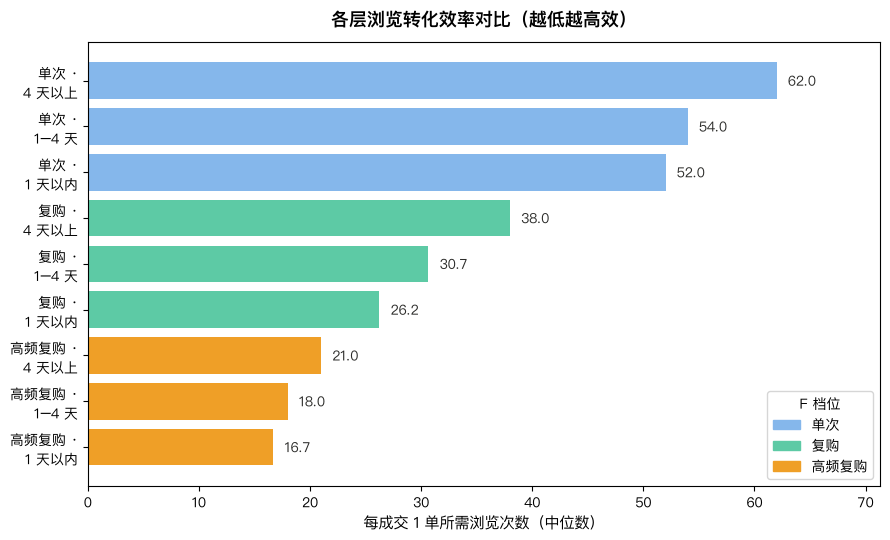

In [60]:
# 6.5 可视化（二）：各层「每成交 1 单所需浏览次数」中位数（实现已抽至 rfm.py）
plot_segment_efficiency(rfm)


**买得越多的人，每成交一单所需的浏览次数反而越少。**

高频复购层每成交一单仅需 16.8–21 次浏览，复购层 26–38 次，单次层 52–62 次。每单所需的浏览次数随购买频次上升而下降，跨度近 4 倍，九层无一例外。也就是说，浏览决策成本最高的用户，恰恰是仅发生单次购买的群体；而高频买家目标明确，决策路径更短。

购买结构同样呈现梯度：单次层的去重商品数为 1，复购层约 2.3 件，高频复购层 5–7 件；购买天数也从 1 天、1.7–2 天上升至 2.3–3.9 天。高频买家的购买行为不仅体现为单次购买的规模更大，还体现为跨越多日、持续复购。

加购行为是另一处值得关注的差异。平均加购次数随频次档位递增——单次层 4–5 次、复购层 5–6 次、高频复购层 9–10 次。其中"高频复购 · 4 天以上"一层平均加购 9.8 次、浏览 135 次，均为九层最高，却在窗口后半段停止购买。结合 5.4 节的结论（加购是三类行为中唯一对购买有正向作用的行为），该层 235 人是加购召回价值最高的人群。

此外，"4 天以上"这一档内部的差异容易被忽略：三个频次层的浏览投入接近（86 / 108 / 135 次），但购买次数分别为 1.00、2.35、5.83，产出相差近 6 倍。因此不能将"4 天以上"统一视为一类——其中既有本就无意复购的用户，也有暂时未回购的用户，还有高意向却未完成下单的用户。

| 层 | **值得关注的信号**                                                          |
| :--- |:----------------------------------------------------------------------------|
| 复购 · 1–4 天 | 人最多的那拨，买得不急不慢，就是最普通的一批买家                            |
| 单次 · 4 天以上 | 很早就买过一次，逛了 86 次东西却再没下单，之后就再没露面                    |
| 高频复购 · 1–4 天 | 跟天天买的人一样能买，就是最近两天不来了——不是没钱，是缺个再买的理由        |
| 单次 · 1–4 天 | 也只买过一次，但买得不算早，还有机会再勾他一次                              |
| 复购 · 4 天以上 | 会回头买，但最近一次已经过去 5 天半，比中间那批人慢了 3 天多                |
| 高频复购 · 1 天以内 | 买得最多、买得最杂的一批，而且截止那天还在下单                              |
| 复购 · 1 天以内 | 这两天还在买的回头客，人不多，但状态最好                                    |
| 单次 · 1 天以内 | 刚买完第一单，时间太短，还看不出他会不会再来                                |
| 高频复购 · 4 天以上 | 买的次数排第二、逛的次数排第一，却已经 5 天多没下单——最"雷声大雨点小"的一批 |


In [61]:
# 6.5 稳健性检验：以 M_item 替换 F 重跑 9 层（实现已抽至 rfm.py）
# 目的：验证分层结论不依赖「购买规模指标」具体选 F 还是 M_item（承接 6.3 第五节的安排）

rob = compute_segment_robustness(rfm)

print('【用 F 分层】')
print(rob['grid_F'].to_string())
print('\n【用 M_item 分层】')
print(rob['grid_M'].to_string())
print('\n【逐格人数差（M_item − F）】')
print(rob['diff'].to_string())
print(f'\n分层结果完全不变：{rob["n_same"]:,} 人（{rob["n_same"] / len(rfm):.1%}）')
print(f'分层结果发生变化：{rob["n_diff"]:,} 人（{rob["n_diff"] / len(rfm):.1%}）')


【用 F 分层】
F_seg    单次    复购  高频复购
R_seg                  
1 天以内   323   700   736
1–4 天   831  1158   843
4 天以上  1106   757   235

【用 M_item 分层】
M_item    单次    复购  高频复购
R_seg                   
1 天以内    338   713   708
1–4 天    865  1190   777
4 天以上   1133   758   207

【逐格人数差（M_item − F）】
M_item  单次  复购  高频复购
R_seg               
1 天以内   15  13   -28
1–4 天   34  32   -66
4 天以上   27   1   -28

分层结果完全不变：6,491 人（97.0%）
分层结果发生变化：198 人（3.0%）


**稳健性检验解读**

以 M_item 替换 F 重跑 9 层分层，**分层结果完全不变的用户占 97.0%（6,491 人），发生变化的仅 3.0%（198 人）**。各格人数差最大 66 人，方向一致（低档位略增、高频档位略减），原因是 M_item 恒不大于 F，少量"多次购买同一商品"的用户被下移一档。

这验证了 6.3 节的判断：M_item 与 F 高度共线，用哪一个做"购买规模"维度，结论基本一致。**本章的分层不依赖于购买规模指标的具体选法。**

### 6.6 运营建议

基于 6.5 的层间画像与效率差异，对几类重点人群提出以下建议：

| 目标人群 | 建议 | 依据 |
| :--- | :--- | :--- |
| 高频复购 · 4 天以上（235 人） | 加购召回：提醒"购物车里有待结算商品" | 平均加购 9.8 次、浏览 135 次为九层最高，后半段却停止购买 |
| 单次 · 4 天以上（1,106 人） | 先排查首单体验与商品匹配，再决定是否发券 | 浏览 86 次仅成交 1 单，投入不低却不再回来 |
| 单次 · 1–4 天（831 人） | 首购后尽快触发二单权益 | 单次用户随 R 增大而递增，首购后越久越难挽回 |
| 复购 · 4 天以上（757 人） | 按历史购买偏好做定向召回 | 有复购能力（2.4 次）但已 5.6 天未购买 |
| 高频复购 · 1 天以内（736 人） | 以维系体验为主，减少营销打扰 | 购买次数与商品覆盖九层最高，截止日当天仍在购买 |

几点说明：

1. 以上是基于 9 天窗口观察性分层的**方向性建议**，不是已验证的策略；落地前用 A/B 实验（实验组 + 留一部分人不触达的对照组）确认实际效果。
2. 高频层与单次层的诉求不同——前者重在维系、后者重在降低再次下单的阻力，不建议用同一套权益。
3. 判断一条建议是否有效的统一口径：干预后复购率相对对照组是否提升，同时关注退订率、补贴成本是否恶化。


### 6.7 未转化用户池

我们目前的分析聚焦了 **6,689 名购买用户**，但全平台还有 **3,050 名（31.3%）从未购买的用户**。他们不进入 RFM 分层（口径见 6.1），却是第五章"转化漏斗"的另一半。本节用一张表承接 5.3 的四组互斥分组，补上这三组的行为画像。

**口径说明**： 沿用 5.3 的「最深行为」互斥分组：Buy > Cart > Fav > PV，四组人数之和 = 9,739。本节只描述"未购买"三组，购买组已在 6.1–6.6 详述。

In [62]:
# 6.7 未转化用户池：承接 5.3 的互斥分组，补三组画像（实现已抽至 rfm.py）
# 口径同 5.3：Buy > Cart > Fav > PV，四组互斥、填满全部 9,739 名活跃用户

has, prof = build_nonbuyer_profile(df)

n_total = len(has)
print(f"全平台活跃用户 = {n_total:,} 人\n")

nb = has[has['group'] != '购买']
print(f"【未购买三组（共 {len(nb):,} 人，占全平台 {len(nb) / n_total:.1%}）】")
print(prof.round(2).to_string())

# 加购未购买组的加购深度
cart_no_buy = nb[nb['group'] == '加购未购买']
print(f"\n加购未购买组（2,021 人）的加购次数中位数 = {cart_no_buy['cart_cnt'].median():.0f} 次")


全平台活跃用户 = 9,739 人

【未购买三组（共 3,050 人，占全平台 31.3%）】
         人数   平均浏览  平均加购  平均收藏  平均活跃天数  占未购买比例%  占全平台比例%
group                                                   
仅浏览     567  39.47  0.00  0.00    5.83     18.6      5.8
加购未购买  2021  81.58  6.12  2.20    6.76     66.3     20.8
收藏未购买   462  76.28  0.00  7.07    6.62     15.1      4.7

加购未购买组（2,021 人）的加购次数中位数 = 4 次


**未购买三组的构成与画像**

未购买的三组行为投入差异明显：

- **加购未购买（2,021 人）**是最大的一块，占未购买用户的 **66.3%**。他们平均加购 6.1 次、浏览 81.6 次，投入最深、意向最明确，加购次数中位数也有 4 次——不是"点一下就走"，而是认真挑过却没下单。结合 5.4 节"加购是三类行为中唯一对购买有正向作用的行为"，这批人是全平台召回价值最高的未转化人群。
- **收藏未购买（462 人）**平均收藏 7.1 次却一单未买，印证了 5.4 的结论——收藏更多是"种草、观望"，购买意向明显弱于加购。
- **仅浏览（567 人）**平均只浏览 39.5 次、活跃 5.8 天，投入最浅，召回优先级最低。

**未购买用户的运营建议**

6.6 的运营建议针对的是"买过、但需要提频或召回"的人；本节这三组是"从没买过"的人，属于**首购转化**问题，动作不同——前者是"让买过的人再买一次"，后者是"让没买过的人迈出第一单"。

如果要把运营动作扩展到这三组，应优先从"加购未购买"组下手做首购转化实验（提醒"购物车里有商品"），方法与 6.6 一致：留一部分人不触达作对照，看触达后 7 天内首购率是否相对提升。


## 第七章：用户群体行为差异的显著性检验（关联性假设检验）

**目标：**
- 用假设检验验证前 6 章发现的组间差异是否统计显著，为运营方向提供数据支撑。

**边界：**
- 本数据为 9 天观测快照（无随机分流、无干预、无对照）
- **我们只看“关联”、“差异”等结论**，不会说“因果”、“收益”这样的结论；更不会使用“导致”、“提高”、“提升 X%”等量化措辞。
如需因果验证，须另设随机对照实验（见章末「局限与展望」）。

**本章的三个假设：**
- 前 6 章已经发现三处「看着有差异」的对比，但都只算了数字、
没验过显著性。这一章逐个回答：这个差异到底是不是真的、有多大。
 - **H1｜加购是不是「要买」的强信号？**<br>
加购过的人，比从没加购过的人，购买率更高吗？
→ 对比「加购过 vs 从未加购」两群人的购买率；来自 5.4（已看到 Lift 1.12，但没验显著性）。
  - **H2｜老客下单是不是比新客更容易「直接下单、不先逛」？**<br>
 「干脆」= 不浏览、不收藏、不加购，直接下单（零间隙购买）。
买过多次的人，比只买过一次的人，更容易「零间隙直接买」吗？
→ 对比「只买 1 次 vs 买 ≥2 次」的零间隙发生率；来自 4.1(B)（已看到 28% vs 5.4%）。
 - **H3｜老客下单前是不是「逛得更少」？**<br>
同样成交一单，买得多的人（高频），比只买一次的人，浏览更少吗？
→ 对比「高频(F≥4) vs 低频(F=1)」每成交一单所需的浏览次数；来自 6.5（已看到 16.8–21 vs 52–62 次）。

### 7.1 口径注册

这一章的三个假设，分别从 5.4 / 4.1(B) / 6.5 把「差异」接过来继续往下做，
但**算法口径跟前几章不完全一样**——所以开工前先把口径钉死，免得最后数字对不上、以为算错了。

| 假设 | 分组方式                      | 算什么 | 为什么跟前几章数字不一样 |
|---|-------------------------------|---|---|
| H1 加购 vs 未加购 | 加购过的人 / 从没加购过的人   | 各自「买过没」的比例 | 这里只看「加购过的人里有多少买过」，不要求先加购后买。结果 72.40%，比 5.4 的 64.09% 高——高出的那部分是「先买后加购」的人 |
| H2 首购 vs 复购零间隙 | 只买过 1 次 / 买过 ≥2 次      | 各自「有没有直接下单（零间隙）」的比例 | 按人算、不按订单算。结果 3.27% vs 39.99%，跟 4.1(B) 按订单算的 5.4% / 28% 是两套数 |
| H3 高频 vs 低频每单浏览 | 高频（买≥4次）/ 低频（买1次） | 每成交一单平均浏览几次 | 这个指标只有「买过的人」才有，样本是 6,689 个买家，不含 3,050 个没买过的；分布右偏，用非参检验 |

**检验方法：**
- H1、H2 比「比例」→ 两比例 Z 检验，效应量看 Cohen's h；
- H3 比「逛多少次」（连续、右偏）→ Mann-Whitney U，效应量看 Cliff's delta。

**假设的结论格式：**
- 点估计 + 95% 置信区间 + p 值 （**不会只参考p值**）。

**注意：**
- 这份数据 6,689~9,739 人，样本够大，p 值基本都会 <0.001（几乎必显著）。
所以这章真正要看的不是「显不显著」，而是**差异到底有多大（效应量）**&#8203;——p 值只是参考方式之一，更要结合效应量来评估。


In [63]:
# 统计工具， 复用最上面 cell-1、cell-5 已加载的）
TOTAL_USERS = df['user_id'].nunique()          # 9,739 全平台活跃用户
N_BUYERS = df[df['behavior_type'] == 'buy']['user_id'].nunique()  # 6,689 买家


def two_prop_test(x1, n1, x2, n2, alpha=0.05):
    """两独立样本比例 Z 检验 + Wald 95% CI + Cohen's h。

    说明：scipy 1.18 起 proportions_ztest 已移至 statsmodels.stats.proportion，
    此处手写等价实现（pooled SE 的 Z 检验），避免额外依赖 statsmodels。

    返回 dict：p1/p2 两率、diff 率差、z、p、ci(率差 95%CI)、cohen_h。
    """
    p1, p2 = x1 / n1, x2 / n2
    p_pool = (x1 + x2) / (n1 + n2)
    se = np.sqrt(p_pool * (1 - p_pool) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    pval = 2 * (1 - stats.norm.cdf(abs(z)))

    se_diff = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    zc = stats.norm.ppf(1 - alpha / 2)
    ci_lo, ci_hi = (p1 - p2) - zc * se_diff, (p1 - p2) + zc * se_diff

    # Cohen's h：2*arcsin(√p1) - 2*arcsin(√p2)；阈值 0.2小 / 0.5中 / 0.8大
    h = 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))
    return {'p1': p1, 'p2': p2, 'diff': p1 - p2, 'z': z,
            'p': pval, 'ci': (ci_lo, ci_hi), 'cohen_h': h}


def cliffs_delta(a, b):
    """Cliff's delta（两组连续量的效应量）：(P(a>b) - P(a<b))。

    阈值 |δ|：0.147 小 / 0.33 中 / 0.47 大。O(n log m)，用 searchsorted 计数。
    """
    a = np.sort(np.asarray(a, dtype=float))
    b = np.sort(np.asarray(b, dtype=float))
    n, m = len(a), len(b)
    gt = sum(np.searchsorted(b, x, side='left') for x in a)   # a 中大于 b 的计数
    lt = sum(m - np.searchsorted(b, x, side='right') for x in a)
    return (gt - lt) / (n * m)


### 7.2 H1 检验：加购的人，是不是更可能买？

**要检验的问题：** 一个用户把商品加进购物车了，ta下单的概率，是不是明显比从没加购过的人高？

**假设：**
- **H0：** 加购用户和未加购用户的购买率**没差别**（p_加购 = p_未加购）
- **H1：** 加购用户和未加购用户的购买率**有差别**（p_加购 ≠ p_未加购）

**验证方式：** 把全平台用户分成「加购过」和「从没加购过」两组，比一比谁的购买率更高，再做两比例 Z 检验。
**这是 5.4 的延续：** 5.4 已经看到加购是三类行为里唯一对购买有正向作用的（Lift 1.12），但当时只算了数、没验显著性。

In [64]:
# H1 加购 vs 未加购 → 购买率（用户级·集合口径）
cart_users = set(df.loc[df['behavior_type'] == 'cart', 'user_id'])
buy_users  = set(df.loc[df['behavior_type'] == 'buy', 'user_id'])
all_users  = set(df['user_id'])

n_cart     = len(cart_users)                    # 有过加购的用户
n_nocart   = len(all_users - cart_users)        # 从未加购的用户
x_cart     = len(cart_users & buy_users)        # 加购且购买
x_nocart   = len((all_users - cart_users) & buy_users)

r = two_prop_test(x_cart, n_cart, x_nocart, n_nocart)

print(f"加购组   购买率 {x_cart:>5,} / {n_cart:,} = {r['p1']*100:.2f}%")
print(f"未加购组 购买率 {x_nocart:>5,} / {n_nocart:,} = {r['p2']*100:.2f}%")
print(f"率差 = {r['diff']*100:.2f} pp，95%CI = [{r['ci'][0]*100:.2f}, {r['ci'][1]*100:.2f}] pp")
print(f"Z = {r['z']:.2f}，p = {r['p']:.2e}")
print(f"Cohen's h = {r['cohen_h']:.3f}（0.2小/0.5中/0.8大） | Lift = {r['p1']/r['p2']:.3f}")


加购组   购买率 5,302 / 7,323 = 72.40%
未加购组 购买率 1,387 / 2,416 = 57.41%
率差 = 14.99 pp，95%CI = [12.77, 17.21] pp
Z = 13.78，p = 0.00e+00
Cohen's h = 0.316（0.2小/0.5中/0.8大） | Lift = 1.261


**H1 结论解读：加购 vs 未加购的购买率**

- **P 值 << 0.001,** 极显著, **Z = 13.78**，说明加购的购买率和未加购的购买率是不一样的。所以 **拒绝 H0**（p_加购 = p_未加购)。

- **两组购买率差值的 95% CI = [12.77, 17.21]**, 百分点最保守的下界 12.77 都大于 0，而 0 代表"没差别"，所以"真实差距是 0"这件事被排除了。**还是拒绝 H0**。

- **样本太大，光看 P 值会骗人。** 7,323 对 2,416 这么大的样本，哪怕只差 1 个百分点，P 值也会小到看不见。所以 P 值显著 ≠ 差异很大，这里必须看效应量：**Cohen's h = 0.316，落在「中等」档。**

- **结论：** 加购和更高购买率确实相关 **（拒绝 H0），但只是中等关联**——h=0.316 意味着加购能当个「这人想买」的参考信号，远没到「加购了基本就会买」。所以 H1 最终判断：**加购的人购买率确实更高，但是购买意愿的强度根据效应量显示为中等，所以不能过度解读。**


### 7.3 H2 检验：复购的老客，是不是比首购的新客更经常「直接下单、不先逛」？

**要检验的问题：** 买过多次的老客，下单前是不是更少逛，更容易零间隙直接买（下单前 0 次 pv/fav/cart）？

**口径跟 4.1 不同：** 4.1(B) 是**按订单**算的零间隙率（首购 5.4% vs 复购 28.0%），但同一人多笔复购不独立，直接拿去检验会虚增样本。所以 H2 换成**按人**算：
- 买家分两组——「只买 1 次」的新客（2,260 人）、「买 ≥2 次」的老客（4,429 人）；
- 零间隙 = 这个人有没有发生过「下单前完全没逛」的购买（新客看唯一那次，老客看复购那几次）。

**假设：**
- **H0：** 新客和老客的零间隙率**没差别**；
- **H1：** 有差别（老客更容易零间隙直接买）。

**验证方式：** 两比例 Z 检验 + Cohen's h（效应量）。

In [65]:
# H2 首购 vs 复购 → 零间隙率（用户级；compute_pre_purchase_gaps 已在 cell-4 import）
pre  = compute_pre_purchase_gaps(df)                    # user_id, purchase_seq, gap_before_purchase
freq = pre.groupby('user_id')['purchase_seq'].max()     # 每个买家一共买了几次

first_buyers  = freq[freq == 1].index                    # 新客：只买 1 次
repeat_buyers = freq[freq >= 2].index                    # 老客：买 ≥2 次

# 新客：唯一那次购买是否零间隙
n_first = len(first_buyers)
x_first = int((pre[pre['user_id'].isin(first_buyers)]['gap_before_purchase'] == 0).sum())

# 老客：复购订单（第 2+ 次）里，有没有至少一次零间隙
repeat_pre = pre[pre['user_id'].isin(repeat_buyers) & (pre['purchase_seq'] >= 2)]
n_repeat = len(repeat_buyers)
x_repeat = int(repeat_pre[repeat_pre['gap_before_purchase'] == 0]['user_id'].nunique())

r = two_prop_test(x_first, n_first, x_repeat, n_repeat)

print(f"新客（只买1次） 零间隙 {x_first:>5,} / {n_first:,} = {r['p1']*100:.2f}%")
print(f"老客（买≥2次）  零间隙 {x_repeat:>5,} / {n_repeat:,} = {r['p2']*100:.2f}%")
print(f"率差 = {r['diff']*100:.2f} pp，95%CI = [{r['ci'][0]*100:.2f}, {r['ci'][1]*100:.2f}] pp")
print(f"Z = {r['z']:.2f}，p = {r['p']:.2e}")
print(f"Cohen's h = {r['cohen_h']:.3f}（0.2小/0.5中/0.8大；负号=老客更高）")


新客（只买1次） 零间隙    74 / 2,260 = 3.27%
老客（买≥2次）  零间隙 1,771 / 4,429 = 39.99%
率差 = -36.71 pp，95%CI = [-38.33, -35.09] pp
Z = -31.78，p = 0.00e+00
Cohen's h = -1.005（0.2小/0.5中/0.8大；负号=老客更高）


**H2 结论解读：老客 vs 新客的零间隙率**

- **P 值 << 0.001,** 极显著, **Z = -31.78**，说明新客和复购买家零间隙率不一样这件事，确定到不能再确定。所以 **拒绝 H0**。

- **两组率差（新客 − 老客）的 95% CI = [-38.33, -35.09]** 个百分点，上下界都是负的、都离 0 很远，说明「两组没差别（差 = 0）」被排除，**还是拒绝 H0**。

- **样本太大，不能光看p值，还要看效应量。**&#8203; Cohen's h = -1.005，负号表示新顾客零间隙率远小于老顾客的零间隙率，**绝对值 = 1.005 > 0.8**；这是三个假设里效应量最大的一个。

- **结论：** 老客零间隙率 39.99%，新客只有 3.27%——**差了 12 倍**。这不是「有点差别」，是**两种完全不同的下单模式**：老客大多直接回购（决策路径极短），新客几乎都要先逛一圈才敢买。

- **一个要交代的口径瑕疵（不影响结论）：** 新客的「零间隙」看的是窗口内第一次购买，受左删失影响——11/25 之前他可能早就逛过了，只是我们看不到，所以 3.27% 是**高估**（有些新客 11/25 之前就逛过、窗口内才下单，被我们误判成「零间隙」；真实新客零间隙只会更低、更接近 0）。 并且这会让「新客几乎不零间隙」的结论更站得住；老客 39.99% 是窗口内真实观测、不受删失影响。方向铁定，量级也不会变。

- **业务洞察：** 老客是「回购型」，新客是「逛街型」。对新客不指望「直接下单」，重点是缩短ta从浏览到下单的路径；对老客，把「一键复购、常购清单」做顺手，放大他本来就有的零间隙回购惯性。


### 7.4 H3 检验：高频买家是不是每单逛得更少

**要检验的问题：** 同样成交一单，买得多的人（高频）是不是比只买一次的人（低频）浏览更少？

**口径：** 买过的 6,689 人里，「每成交一单平均浏览几次」= pv_cnt ÷ Frequency。这个指标是连续量、且右偏，所以不用 Z 检验，改用非参数检验。

**假设：**
- **H0：** 高频和低频买家「每单浏览数」分布**没差别**；
- **H1：** 有差别（高频买家每单浏览更少）。

**验证方式：** Mann-Whitney U 检验 + Cliff's delta（效应量）。


In [66]:
# H3 高频 vs 低频 → 每单浏览数（用户级）
rfm = build_buyer_rfm(df)
per_buy = rfm['pv_cnt'] / rfm['Frequency']              # 每成交一单平均浏览几次

low  = per_buy[rfm['Frequency'] == 1]                   # 低频：只买 1 次
high = per_buy[rfm['Frequency'] >= 4]                   # 高频：买 ≥4 次

u, p = stats.mannwhitneyu(high, low, alternative='two-sided')
d = cliffs_delta(high, low)

print(f"低频组(F=1)   n={len(low):,}   每单浏览中位数 {low.median():.1f} 次")
print(f"高频组(F>=4)  n={len(high):,}  每单浏览中位数 {high.median():.1f} 次")
print(f"中位差 = {low.median()-high.median():.1f} 次")
print(f"Mann-Whitney U = {u:.0f}，p = {p:.2e}")
print(f"Cliff's delta = {d:.3f}（|δ|：0.147小/0.33中/0.47大；负号=高频组更少）")


低频组(F=1)   n=2,260   每单浏览中位数 58.0 次
高频组(F>=4)  n=1,814  每单浏览中位数 18.0 次
中位差 = 40.0 次
Mann-Whitney U = 715239，p = 3.39e-280
Cliff's delta = -0.651（|δ|：0.147小/0.33中/0.47大；负号=高频组更少）


**H3 结论解读：高频 vs 低频买家的每单浏览数**

- Mann-Whitney U 检验的 **P = 3.4e-280 << 0.001**， 所以高频低频每单浏览数不一样，**拒绝 H0**。

- 低频组每单中位数 58 次、高频组中位数 18 次，差了 40 次。

- **样本太大，不能光看p值，还要看效应量。** Cliff's delta = **-0.651**，绝对值 = 0.651 > 0.47，落进「大」档。负号表示高频组每单浏览更少。

- **结论：** 买得越多的人，每成交一单浏览越少——这跟 H2 串起来了：**老客不但更容易零间隙直接买（H2），就算要逛，也逛得更少（H3）**。两条证据指向同一件事：老客的决策路径比新客短得多。

**业务洞察：** 新客靠「逛」建立信任，老客靠「惯性」快速成交。运营动作要分人群：对新客重「种草、比价、打消顾虑」，对老客重「省事、一键回购」。


### 7.5 三个假设的效应量汇总



把三个假设的效应量放一起排个序，看谁才是真正「能区分用户」的信号：

| 假设 | 对比什么 | 效应量 | 定性 | 一句话结论 |
|---|---|---|---|---|
| H1 | 加购 vs 未加购的购买率 | Cohen's h = 0.316 | 中等 | 加购是正向信号，但也就中等 |
| H2 | 老客 vs 新客的零间隙率 | Cohen's h = -1.005 | 超大 | 老客零间隙是新客的 12 倍 |
| H3 | 高频 vs 低频的每单浏览 | Cliff's δ = -0.651 | 大 | 老客每单少逛 40 次 |

> 注：H1/H2 用 Cohen's h、H3 用 Cliff's delta，是两把不同的尺子，**数值不能直接比**，这里按「定性等级」排序。

**排序一目了然：H2（超大）≫ H3（大）> H1（中等）。**&#8203;

这说明**真正把用户区分开的，不是「加不加购」，而是「是不是老客」。**&#8203;

- 加购（H1）只是「中度」信号——加购的人确实更可能买，但和没加购的人差距没大到天壤之别；
- 老客 vs 新客（H2、H3）才是「断层级」差异——老客零间隙率是新客的 12 倍、每单少逛 40 次，两条证据指向同一件事：**老客和新客是两种完全不同的下单模式。**&#8203;

**业务洞察：** 加购只是过程信号，老客身份才是终极结果。对成交的长期贡献，两者差一个量级——我们应该优先分析‘新客如何变老客’，而非 “新客为何不加购”，因为老客带来的边际贡献，远非单次加购可比。。


### 7.6 结论与局限

**结论：**

- **加购是「中度」的购买信号（H1）。**&#8203; 加购过的人购买率 72.40%，比未加购的 57.41% 高 15 个百分点，差异真实存在，但效应量中等， 也就是说可以当参考，但别当铁律。

- **老客和新客是两种下单模式（H2 和 H3）。**&#8203; 老客零间隙率 39.99%（新客 3.27%，差 12 倍）、每单浏览 18 次（新客 58 次，少 40 次）。老客的决策路径远短于新客，这是本章效应量最强的发现。

- **真正值得投入的杠杆是「新客→老客」的转化，不是「浏览→加购」的转化。**&#8203; 老客身份对成交的影响（超大/大效应）远大于加购行为（中等效应）。

**局限与边界：**

- **观测数据，无因果。**&#8203; 没有随机分流、没有干预，所有结论都是「关联」不是「因果」。H2 只能说「老客习惯直接买」，不能证明「零间隙导致了复购」。

- 2. **左删失。**&#8203; 数据从 11/25 起，用户之前的浏览不可见——有些新客窗口前就逛过、窗口内才下单，被误判成「零间隙」，所以新客 3.27% 的零间隙率是**高估**（真实值只会更低）。

- **极端组对比放大效应。**&#8203; H3 只比了 F=1 和 F≥4 两头，过滤了 F=2、F=3，效应量被放大；换「F=1 vs F≥2」口径，δ 会略小。

- **窗口短 + 大促期 + p 值廉价。**&#8203; 只有 9 天、落在双 12 预热期，外推要打折；6,689~9,739 的大样本下 p 值几乎必 <0.001，本章结论全靠效应量撑着。

**下一步：** 这三个假设只能回答「有没有差别、差多大」，回答不了「为什么」。要验证因果（比如「缩短新客决策路径能不能提高首购」），必须另设随机对照实验——这是这份 9 天快照数据做不到的，也是这个项目的边界。